# CS-781 Phase 2: Legal Named Entity Recognition (L-NER)

Development copy based on the prepared V1 notebook. The first development milestone is to keep the Phase 1 architecture/tokenizer intact, isolate Phase 2 outputs, locate the Phase 2 files, and restore the trained V1 checkpoint before implementing the NER pipeline.

**Important:** attach the trained V1 checkpoint and Phase 2 data as Kaggle inputs before running the corresponding cells. This notebook has not been executed in this environment.

## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os

HF_TOKEN = os.environ.get("HF_TOKEN")

try:
    from kaggle_secrets import UserSecretsClient
    kaggle_token = UserSecretsClient().get_secret("HF")
    if kaggle_token:
        HF_TOKEN = kaggle_token
except Exception as exc:
    print("Kaggle HF secret was not available in this environment.")

if HF_TOKEN:
    from huggingface_hub import login
    os.environ["HF_TOKEN"] = HF_TOKEN
    login(token=HF_TOKEN, add_to_git_credential=False)
    print("Hugging Face authentication configured.")
else:
    print("No HF token found. Public dataset access may still work; gated access will require a token and accepted dataset terms.")


Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [3]:
#VERSION 1: DECODER ONLY MODEL; using GQA+ROPE+RMSNORM

import os
import random
import json
import time
import math
import zipfile
import shutil
import torch
import numpy as np

SEED =42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("Basic setup loaded.")
print(f"Random seed: {SEED}")

Basic setup loaded.
Random seed: 42


In [4]:
#DATASET
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

#for this version i am using just the supreme court training files
TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE ="Phase_1_Pretraining/Test/test.json"

#for this version i was not sure of the computation timing so taking just 100M tokens
TRAIN_TOKENS = 100_000_000
VAL_TOKENS = 5_000_000

print("Dataset settings loaded.")
print("Training file:", TRAIN_FILE)
print("Training tokens:", f"{TRAIN_TOKENS:,}")
print("Validation tokens:", f"{VAL_TOKENS:,}")

Dataset settings loaded.
Training file: Phase_1_Pretraining/Train/train_supreme_court.json
Training tokens: 100,000,000
Validation tokens: 5,000,000


In [5]:
#context length basically tells us about how many tokens it can look at in one traing example
MODEL_CONTEXT_LENGTH=1024
TRAIN_BLOCK_SIZE = MODEL_CONTEXT_LENGTH
print("CL:", MODEL_CONTEXT_LENGTH)
print("Training block size:", TRAIN_BLOCK_SIZE)

CL: 1024
Training block size: 1024


In [6]:
#ARCHITECTURE
#Using 12 layers for a deeper model
N_LAYER=12
N_EMBD=768 #every token will be represented using 768 numbers inside the model
N_HEAD=12

#Number of key/value heads
#12 query heads will share 4 key heads and 4 value heads
N_KV_HEAD=4

#using normal feed-forward network
FFN_MULTIPLIER=4
DROPOUT=0.0
USE_ROPE= True
USE_RMSNORM = True

#sanity check
print("Model architecture settings loaded.")
print(f"Layers: {N_LAYER}")
print(f"Hidden size: {N_EMBD}")
print(f"Query heads: {N_HEAD}")
print(f"Key/Value heads: {N_KV_HEAD}")

Model architecture settings loaded.
Layers: 12
Hidden size: 768
Query heads: 12
Key/Value heads: 4


In [7]:
#TRAINING SETTINGS
PER_DEVICE_BATCH_SIZE=4
#To avoid any error as GPU might not be able to fit the large batch directly
GRADIENT_ACCUMULATION_STEPS=8
LEARNING_RATE = 3e-4
WEIGHT_DECAY=0.1
WARMUP_STEPS=500          #The learning rate inreases slowly instead of immediately using the entire value from start
MAX_GRAD_NORM=1000
EVAL_EVERY_STEPS=1000        #validation loss check frequency
LOG_EVERY_STEPS=100    #Print frequency
SAVE_EVERY_STEPS=1000
MAX_CHECKPOINTS_TO_KEEP=5
USE_AMP =torch.cuda.is_available()
USE_GRADIENT_CHECKPOINTING = False

#sanity check
print("Training settings loaded.")
print("Batch size:", PER_DEVICE_BATCH_SIZE)
print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)
print("Effective batch size:",PER_DEVICE_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Learning rate:", LEARNING_RATE)

Training settings loaded.
Batch size: 4
Gradient accumulation: 8
Effective batch size: 32
Learning rate: 0.0003


In [8]:
#Generation and output settings

TARGET_GENERATION_WORDS=128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.7            #The starter uses 0.1, but its predictions showed strong repetition, so i am experimenting it
TOP_P =0.95
TOP_K=50 #adding this as an experiment
REPETITION_PENALTY=1.1 #Adding a penalty as the predictions showed heavy repetition

#OUTPUT and CHECKPOINT PATHS

OUTPUT_DIR = "/kaggle/working/cs781_phase1_v1"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "checkpoints")
CACHE_DIR = os.path.join(OUTPUT_DIR, "cache")
LOG_DIR = os.path.join(OUTPUT_DIR, "logs")
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "final_model")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
CONFIG_PATH = os.path.join(OUTPUT_DIR, "config.json")

for directory in[
    OUTPUT_DIR,CHECKPOINT_DIR,CACHE_DIR,LOG_DIR,MODEL_OUTPUT_DIR
]:
    os.makedirs(directory, exist_ok=True)

print("Generation and output settings loaded.")
print("Output directory:", OUTPUT_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Cache directory:", CACHE_DIR)

Generation and output settings loaded.
Output directory: /kaggle/working/cs781_phase1_v1
Checkpoint directory: /kaggle/working/cs781_phase1_v1/checkpoints
Cache directory: /kaggle/working/cs781_phase1_v1/cache


In [ ]:
# Phase 2 output paths. Keep Phase 2 artifacts separate from Phase 1.
EXPERIMENT_NAME = "V1_FullFT"
PHASE2_ROOT_DIR = "/kaggle/working/cs781_phase2_lner"
PHASE2_OUTPUT_DIR = os.path.join(PHASE2_ROOT_DIR, EXPERIMENT_NAME)
PHASE2_CHECKPOINT_DIR = os.path.join(PHASE2_OUTPUT_DIR, "checkpoints")
PHASE2_PREDICTION_PATH = os.path.join(PHASE2_OUTPUT_DIR, "prediction.json")
PHASE2_SUBMISSION_ZIP = os.path.join(PHASE2_OUTPUT_DIR, "submission.zip")

os.makedirs(PHASE2_CHECKPOINT_DIR, exist_ok=True)

print("Experiment:", EXPERIMENT_NAME)
print("Phase 2 output directory:", PHASE2_OUTPUT_DIR)
print("Phase 2 checkpoint directory:", PHASE2_CHECKPOINT_DIR)

In [9]:
#Experiment configuration
#this is to keep a track of my experiments and implemntations so that they donot mix up with the future ones

experiment_config = {
    "seed": SEED,

    # Dataset
    "dataset": HF_DATASET_REPO,
    "train_file": TRAIN_FILE,
    "train_tokens": TRAIN_TOKENS,
    "val_tokens": VAL_TOKENS,

    # Sequence length
    "context_length": MODEL_CONTEXT_LENGTH,
    "block_size": TRAIN_BLOCK_SIZE,

    # Model architecture
    "n_layer": N_LAYER,
    "n_embd": N_EMBD,
    "n_head": N_HEAD,
    "n_kv_head": N_KV_HEAD,
    "ffn_multiplier": FFN_MULTIPLIER,
    "dropout": DROPOUT,
    "use_rope": USE_ROPE,
    "use_rmsnorm": USE_RMSNORM,

    # Training
    "batch_size": PER_DEVICE_BATCH_SIZE,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_steps": WARMUP_STEPS,
    "max_grad_norm": MAX_GRAD_NORM,
    "eval_every_steps": EVAL_EVERY_STEPS,
    "log_every_steps": LOG_EVERY_STEPS,
    "save_every_steps": SAVE_EVERY_STEPS,
    "max_checkpoints_to_keep": MAX_CHECKPOINTS_TO_KEEP,
    "use_amp": USE_AMP,

    # Generation
    "target_generation_words": TARGET_GENERATION_WORDS,
    "max_generation_tokens": MAX_GENERATION_TOKENS,
    "temperature": TEMPERATURE,
    "top_p": TOP_P,
    "top_k": TOP_K,
    "repetition_penalty": REPETITION_PENALTY,
}

## 4. Load Tokenizer

In [10]:
#tokenizer from A1
import os
import json

BPE_FILENAME = "bpe_en_25k.json"
bpe_candidates = []

for root, dirs, files in os.walk("/kaggle/input"):
    if BPE_FILENAME in files:
        bpe_candidates.append(os.path.join(root, BPE_FILENAME))

if len(bpe_candidates) == 0:
    raise FileNotFoundError(
        f"{BPE_FILENAME} was not found inside /kaggle/input/. "
        "Make sure the BPE-25k dataset is attached."
    )

BPE_PATH = bpe_candidates[0]

print("Tokenizer found:", BPE_PATH)


# Load the vocabulary and learned BPE merges.
with open(BPE_PATH, "r", encoding="utf-8") as f:
    bpe_data = json.load(f)

bpe_itos = bpe_data["itos"]
bpe_merges = bpe_data["merges"]
bpe_vocab_size = bpe_data["vocab_size"]

# Make sure we have loaded the tokenizer we actually want.
assert bpe_vocab_size == 25_000
assert len(bpe_itos) == 25_000

print("Vocabulary size:", bpe_vocab_size)
print("Number of merge rules:", len(bpe_merges))


# Token -> ID mapping
bpe_stoi = {
    token: idx
    for idx, token in enumerate(bpe_itos)
}
merge_to_id = {}

for merge_index, merge in enumerate(bpe_merges):
    left_token, right_token = merge

    left_id = bpe_stoi[left_token]
    right_id = bpe_stoi[right_token]

    new_token_id = 261 + merge_index
    merge_to_id[(left_id, right_id)] = new_token_id

PAD_TOKEN_ID = bpe_stoi["<pad>"]
UNK_TOKEN_ID = bpe_stoi["<unk>"]
BOS_TOKEN_ID = bpe_stoi["<s>"]
EOS_TOKEN_ID = bpe_stoi["</s>"]
WORD_BOUNDARY_ID = bpe_stoi["<wb>"]

print("\nSpecial token IDs:")
print("PAD:", PAD_TOKEN_ID)
print("UNK:", UNK_TOKEN_ID)
print("BOS:", BOS_TOKEN_ID)
print("EOS:", EOS_TOKEN_ID)
print("WORD BOUNDARY:", WORD_BOUNDARY_ID)

Tokenizer found: /kaggle/input/datasets/ayushbunnumaharaj/v1-bpe-25k/bpe_en_25k.json
Vocabulary size: 25000
Number of merge rules: 24739

Special token IDs:
PAD: 0
UNK: 1
BOS: 2
EOS: 3
WORD BOUNDARY: 260


In [11]:
#Tokenizer Sanity Check
#Before using the tokenizer on the full legal corpus,let's check a small example and make sure encoding and decoding work correctly.

class ByteLevelBPE25k:
    def __init__(self, itos, stoi, merge_to_id, merges):
        self.itos = itos
        self.stoi = stoi
        self.merge_to_id = merge_to_id
        self.merges = merges
        self.vocab_size = len(itos)

        self.pad_token_id = stoi["<pad>"]
        self.unk_token_id = stoi["<unk>"]
        self.bos_token_id = stoi["<s>"]
        self.eos_token_id = stoi["</s>"]
        self.word_boundary_id = stoi["<wb>"]

    def _encode_word(self, word):
        # Start with the UTF-8 bytes of the word.
        sequence = [
            4 + byte
            for byte in word.encode("utf-8")
        ]

        # Our BPE representation keeps a word-boundary token.
        sequence.append(self.word_boundary_id)

        while len(sequence) > 1:
            best_position = None
            best_token_id = None

            for i in range(len(sequence) - 1):
                pair = (sequence[i], sequence[i + 1])
                new_token_id = self.merge_to_id.get(pair)

                if new_token_id is None:
                    continue

                if (
                    best_token_id is None
                    or new_token_id < best_token_id
                ):
                    best_token_id = new_token_id
                    best_position = i

            if best_position is None:
                break

            i = best_position
            sequence = (
                sequence[:i]
                + [best_token_id]
                + sequence[i + 2:]
            )

        return sequence

    def encode(self, text, add_bos=False, add_eos=False):
        # The original tokenizer was trained word-by-word.
        words = text.split()

        token_ids = []

        if add_bos:
            token_ids.append(self.bos_token_id)

        for word in words:
            token_ids.extend(
                self._encode_word(word)
            )

        if add_eos:
            token_ids.append(self.eos_token_id)

        return token_ids

    def _token_to_bytes(self, token_id):
        token = self.itos[token_id]

        # Raw byte token.
        if token.startswith("<0x") and token.endswith(">"):
            return bytes([int(token[3:-1], 16)])

        if token == "<wb>":
            return b" "

        if token in {"<pad>", "<unk>", "<s>", "</s>"}:
            return b""

        # Learned BPE token.
        if token.startswith("<bpe_"):
            merge_index = token_id - 261

            if 0 <= merge_index < len(self.merges):
                left_token, right_token = self.merges[merge_index]

                left_id = self.stoi[left_token]
                right_id = self.stoi[right_token]

                return (
                    self._token_to_bytes(left_id)
                    + self._token_to_bytes(right_id)
                )

        return b""

    def decode(self, token_ids):
        output = bytearray()

        for token_id in token_ids:
            if not 0 <= int(token_id) < self.vocab_size:
                continue

            output.extend(
                self._token_to_bytes(int(token_id))
            )

        return bytes(output).decode(
            "utf-8",
            errors="replace"
        )


# Creating the tokenizer.
tokenizer = ByteLevelBPE25k(
    itos=bpe_itos,
    stoi=bpe_stoi,
    merge_to_id=merge_to_id,
    merges=bpe_merges
)


# Test it on a small legal-style sentence.
sample_text = (
    "The Supreme Court of India has jurisdiction "
    "over constitutional matters."
)

sample_tokens = tokenizer.encode(sample_text)
decoded_text = tokenizer.decode(sample_tokens)

print("Original text:")
print(sample_text)
print("\nToken IDs:")
print(sample_tokens)
print("\nNumber of tokens:", len(sample_tokens))
print("\nDecoded text:")
print(decoded_text)
print("\nVocabulary size:", tokenizer.vocab_size)
assert tokenizer.vocab_size == 25_000
assert len(sample_tokens) > 0
print("\nTokenizer sanity check passed.")

Original text:
The Supreme Court of India has jurisdiction over constitutional matters.

Token IDs:
[356, 4107, 2786, 280, 633, 431, 7486, 771, 8996, 10403]

Number of tokens: 10

Decoded text:
The Supreme Court of India has jurisdiction over constitutional matters. 

Vocabulary size: 25000

Tokenizer sanity check passed.


In [ ]:
# Resolve Phase 2 files from an attached Kaggle dataset first, then from the official Hugging Face repository.
# The Capstone Document maps phase_2 to the Phase_2_LNER folder.
from huggingface_hub import hf_hub_download

PHASE2_HF_PATHS = {
    "fold1-text.json": "Phase_2_LNER/Train/fold1-text.json",
    "fold1-gold.json": "Phase_2_LNER/Train/fold1-gold.json",
    "fold2-text.json": "Phase_2_LNER/Train/fold2-text.json",
    "fold2-gold.json": "Phase_2_LNER/Train/fold2-gold.json",
    "fold3-text.json": "Phase_2_LNER/Test/fold3-text.json",
    "labels.txt": "Phase_2_LNER/Train/labels.txt",
}

PHASE2_FILES = {}
PHASE2_FILE_SOURCES = {}
PHASE2_RESOLUTION_ERRORS = {}

for filename, hub_filename in PHASE2_HF_PATHS.items():
    local_matches = []
    for search_root in ["/kaggle/input", "/kaggle/working"]:
        if os.path.isdir(search_root):
            for root, dirs, files in os.walk(search_root):
                if filename in files:
                    local_matches.append(os.path.join(root, filename))

    local_matches = sorted(set(local_matches))
    if len(local_matches) == 1:
        PHASE2_FILES[filename] = local_matches[0]
        PHASE2_FILE_SOURCES[filename] = "local"
        print(f"LOCAL   {filename}: {local_matches[0]}")
        continue

    if len(local_matches) > 1:
        print(f"MULTIPLE local copies found for {filename}; trying the official Hugging Face path instead.")

    try:
        downloaded_path = hf_hub_download(
            repo_id=HF_DATASET_REPO,
            filename=hub_filename,
            repo_type="dataset",
            token=HF_TOKEN or None,
        )
        PHASE2_FILES[filename] = downloaded_path
        PHASE2_FILE_SOURCES[filename] = "huggingface"
        print(f"HUGGING FACE {filename}: {downloaded_path}")
    except Exception as exc:
        PHASE2_RESOLUTION_ERRORS[filename] = f"{type(exc).__name__}: {exc}"
        print(f"NOT RESOLVED {filename}: {type(exc).__name__}: {exc}")

PHASE2_REQUIRED_FILENAMES = list(PHASE2_HF_PATHS)
PHASE2_MISSING_FILES = [name for name in PHASE2_REQUIRED_FILENAMES if name not in PHASE2_FILES]
PHASE2_DATA_READY = not PHASE2_MISSING_FILES

print("\nPhase 2 data ready:", PHASE2_DATA_READY)
print("Local files:", sum(v == "local" for v in PHASE2_FILE_SOURCES.values()))
print("Hub files:", sum(v == "huggingface" for v in PHASE2_FILE_SOURCES.values()))

if PHASE2_MISSING_FILES:
    missing_details = "\n".join(
        f"- {name} ({PHASE2_HF_PATHS[name]}): {PHASE2_RESOLUTION_ERRORS.get(name, 'not found')}"
        for name in PHASE2_MISSING_FILES
    )
    raise RuntimeError(
        "Could not resolve all Phase 2 files. Verify that the repository is "
        f"accessible, the HF token has accepted any access conditions, and the file paths match the current dataset.\n{missing_details}"
    )


## 5. Download Training Data From Hugging Face

In [12]:
# from huggingface_hub import hf_hub_download

# train_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO,
#     filename=TRAIN_FILE,
#     repo_type="dataset",
#     token=HF_TOKEN
# )

# print("Training file:")
# print(train_file_path)

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json


## 6. Create Train and Validation Tokens Set

In [13]:
# # 6. Create Train and Validation Token Cache
# import os
# import json
# import random
# import time
# import numpy as np

# CACHE_DIR = os.path.join(
#     OUTPUT_DIR,
#     "token_cache"
# )

# os.makedirs(CACHE_DIR, exist_ok=True)

# TRAIN_TOKEN_PATH = os.path.join(
#     CACHE_DIR,
#     "train_tokens.bin"
# )

# VAL_TOKEN_PATH = os.path.join(
#     CACHE_DIR,
#     "val_tokens.bin"
# )

# TOKEN_CACHE_META = os.path.join(
#     CACHE_DIR,
#     "cache_metadata.json"
# )

# # Load the official training corpus
# with open(train_file_path, "r", encoding="utf-8") as f:
#     records = json.load(f)

# print("Number of records:", len(records))

# # Resume from an existing cache if possible

# train_count = 0
# val_count = 0
# start_record = 0

# if (
#     os.path.exists(TRAIN_TOKEN_PATH)
#     and os.path.exists(VAL_TOKEN_PATH)
#     and os.path.exists(TOKEN_CACHE_META)
# ):
#     with open(TOKEN_CACHE_META, "r", encoding="utf-8") as f:
#         cache_meta = json.load(f)

#     # Make sure this cache belongs to the same experiment.
#     if (
#         cache_meta.get("train_tokens") == TRAIN_TOKENS
#         and cache_meta.get("val_tokens") == VAL_TOKENS
#         and cache_meta.get("vocab_size") == tokenizer.vocab_size
#         and cache_meta.get("seed") == SEED
#     ):
#         start_record = cache_meta["next_record"]
#         train_count = cache_meta["train_count"]
#         val_count = cache_meta["val_count"]

#         print("Existing token cache found.")
#         print("Resuming from record:", start_record)
#         print("Train tokens already cached:", f"{train_count:,}")
#         print("Validation tokens already cached:", f"{val_count:,}")

#     else:
#         print("Existing cache does not match the current settings.")
#         print("Starting a fresh token cache.")

#         os.remove(TRAIN_TOKEN_PATH)
#         os.remove(VAL_TOKEN_PATH)
#         os.remove(TOKEN_CACHE_META)

# else:
#     print("No existing token cache found.")
#     print("Starting tokenization from the beginning.")

# # Open cache files in append mode

# train_file = open(
#     TRAIN_TOKEN_PATH,
#     "ab"
# )

# val_file = open(
#     VAL_TOKEN_PATH,
#     "ab"
# )

# # Tokenize the corpus
# # We keep the same record-level random split used earlier:roughly 95% for training and 5% for validation.The seed and record index are saved, so the split stays fixed when the process is resumed.

# random.seed(SEED)

# # Recreate the same random decisions for records that were
# # already processed before an interruption.
# for _ in range(start_record):
#     random.random()

# start_time = time.time()

# for record_index in range(start_record, len(records)):

#     # Stop once both requested token budgets are reached.
#     if (
#         train_count >= TRAIN_TOKENS
#         and val_count >= VAL_TOKENS
#     ):
#         break

#     text = records[record_index]["text"]

#     # Use our custom BPE-25k tokenizer.
#     tokens = tokenizer.encode(
#         text,
#         add_bos=False,
#         add_eos=False
#     )

#     # Decide whether this record belongs to validation.
#     is_validation = random.random() < 0.05

#     if is_validation and val_count < VAL_TOKENS:

#         remaining = VAL_TOKENS - val_count
#         tokens = tokens[:remaining]

#         if tokens:
#             token_array = np.asarray(
#                 tokens,
#                 dtype=np.uint32
#             )

#             val_file.write(
#                 token_array.tobytes()
#             )

#             val_count += len(token_array)

#     elif not is_validation and train_count < TRAIN_TOKENS:

#         remaining = TRAIN_TOKENS - train_count
#         tokens = tokens[:remaining]

#         if tokens:
#             token_array = np.asarray(
#                 tokens,
#                 dtype=np.uint32
#             )

#             train_file.write(
#                 token_array.tobytes()
#             )

#             train_count += len(token_array)


#     # Save progress periodically so an interruption does notforce us to start tokenization from zero.
#     if (
#         (record_index + 1) % 100 == 0
#         or train_count >= TRAIN_TOKENS
#         or val_count >= VAL_TOKENS
#     ):

#         train_file.flush()
#         val_file.flush()

#         cache_meta = {
#             "train_tokens": TRAIN_TOKENS,
#             "val_tokens": VAL_TOKENS,
#             "train_count": train_count,
#             "val_count": val_count,
#             "next_record": record_index + 1,
#             "vocab_size": tokenizer.vocab_size,
#             "seed": SEED
#         }

#         with open(
#             TOKEN_CACHE_META,
#             "w",
#             encoding="utf-8"
#         ) as f:
#             json.dump(
#                 cache_meta,
#                 f,
#                 indent=2
#             )

#     # Print progress every 100 records.
#     if (record_index + 1) % 100 == 0:

#         elapsed = time.time() - start_time

#         print(
#             f"Record {record_index + 1:,}/{len(records):,} | "
#             f"Train: {train_count:,}/{TRAIN_TOKENS:,} | "
#             f"Val: {val_count:,}/{VAL_TOKENS:,} | "
#             f"Time: {elapsed / 60:.1f} min"
#         )


# train_file.flush()
# val_file.flush()

# train_file.close()
# val_file.close()

# # Final checks

# assert train_count == TRAIN_TOKENS, (
#     f"Expected {TRAIN_TOKENS:,} train tokens, "
#     f"got {train_count:,}"
# )

# assert val_count == VAL_TOKENS, (
#     f"Expected {VAL_TOKENS:,} validation tokens, "
#     f"got {val_count:,}"
# )

# print("\nTokenization complete.")
# print("Train tokens:", f"{train_count:,}")
# print("Validation tokens:", f"{val_count:,}")
# print("Train cache:", TRAIN_TOKEN_PATH)
# print("Validation cache:", VAL_TOKEN_PATH)

Number of records: 55549
No existing token cache found.
Starting tokenization from the beginning.
Record 100/55,549 | Train: 587,544/100,000,000 | Val: 33,483/5,000,000 | Time: 0.0 min
Record 200/55,549 | Train: 1,095,652/100,000,000 | Val: 52,782/5,000,000 | Time: 0.1 min
Record 300/55,549 | Train: 1,658,617/100,000,000 | Val: 70,685/5,000,000 | Time: 0.1 min
Record 400/55,549 | Train: 2,171,888/100,000,000 | Val: 89,387/5,000,000 | Time: 0.2 min
Record 500/55,549 | Train: 2,860,061/100,000,000 | Val: 130,113/5,000,000 | Time: 0.2 min
Record 600/55,549 | Train: 3,754,146/100,000,000 | Val: 159,737/5,000,000 | Time: 0.3 min
Record 700/55,549 | Train: 4,675,444/100,000,000 | Val: 171,764/5,000,000 | Time: 0.4 min
Record 800/55,549 | Train: 5,772,894/100,000,000 | Val: 180,154/5,000,000 | Time: 0.5 min
Record 900/55,549 | Train: 6,486,312/100,000,000 | Val: 196,425/5,000,000 | Time: 0.5 min
Record 1,000/55,549 | Train: 7,340,498/100,000,000 | Val: 248,932/5,000,000 | Time: 0.6 min
Record

## 7. Create Token Blocks

In [14]:
# # Create Dataset From Cached Tokens

# import numpy as np
# import torch
# from torch.utils.data import Dataset

# class LegalTokenDataset(Dataset):
#     def __init__(
#         self,
#         token_path,
#         num_tokens,
#         block_size,
#         stride=1
#     ):
#         self.token_path = token_path
#         self.num_tokens = num_tokens
#         self.block_size = block_size
#         self.stride = stride

#         # The file stays on disk and is accessed only when
#         # a particular training example is requested.
#         self.tokens = np.memmap(
#             token_path,
#             dtype=np.uint32,
#             mode="r",
#             shape=(num_tokens,)
#         )

#     def __len__(self):
#         return 1 + (
#             self.num_tokens
#             - self.block_size
#             - 1
#         ) // self.stride

#     def __getitem__(self, index):
#         start = index * self.stride
#         end = start + self.block_size + 1

#         tokens = self.tokens[start:end].astype(
#             np.int64
#         )

#         input_ids = torch.from_numpy(
#             tokens[:-1]
#         )

#         labels = torch.from_numpy(
#             tokens[1:]
#         )

#         return {
#             "input_ids": input_ids,
#             "labels": labels
#         }

# train_dataset = LegalTokenDataset(
#     token_path=TRAIN_TOKEN_PATH,
#     num_tokens=TRAIN_TOKENS,
#     block_size=TRAIN_BLOCK_SIZE,
#     stride=1
# )

# val_dataset = LegalTokenDataset(
#     token_path=VAL_TOKEN_PATH,
#     num_tokens=VAL_TOKENS,
#     block_size=TRAIN_BLOCK_SIZE,
#     stride=TRAIN_BLOCK_SIZE
# )

# print("Train examples:", f"{len(train_dataset):,}")
# print("Validation examples:", f"{len(val_dataset):,}")
# print("Sequence length:", TRAIN_BLOCK_SIZE)

Train examples: 99,998,976
Validation examples: 4,882
Sequence length: 1024


## 8. Create Datasets

In [15]:
# from torch.utils.data import DataLoader

# train_loader = DataLoader(
#     train_dataset,
#     batch_size=PER_DEVICE_BATCH_SIZE,
#     shuffle=True,
#     num_workers=2,
#     pin_memory=True,
#     drop_last=True
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=PER_DEVICE_BATCH_SIZE,
#     shuffle=False,
#     num_workers=2,
#     pin_memory=True,
#     drop_last=True
# )

# print("Train batches per epoch:", len(train_loader))
# print("Validation batches:", len(val_loader))
# print("Batch size:", PER_DEVICE_BATCH_SIZE)
# print("Gradient accumulation:", GRADIENT_ACCUMULATION_STEPS)

Train batches per epoch: 24999744
Validation batches: 1220
Batch size: 4
Gradient accumulation: 8


In [16]:
# #SANITY CHECK
# batch = next(iter(train_loader))

# print("Input shape:", batch["input_ids"].shape)
# print("Label shape:", batch["labels"].shape)

# print(
#     "Minimum token ID:",
#     batch["input_ids"].min().item()
# )

# print(
#     "Maximum token ID:",
#     batch["input_ids"].max().item()
# )

# assert batch["input_ids"].shape == (
#     PER_DEVICE_BATCH_SIZE,
#     TRAIN_BLOCK_SIZE
# )
# assert batch["labels"].shape == (
#     PER_DEVICE_BATCH_SIZE,
#     TRAIN_BLOCK_SIZE
# )
# assert batch["input_ids"].min() >= 0
# assert batch["input_ids"].max() < tokenizer.vocab_size

# print("\nDataLoader sanity check passed.")

Input shape: torch.Size([4, 1024])
Label shape: torch.Size([4, 1024])
Minimum token ID: 38
Maximum token ID: 24954

DataLoader sanity check passed.


## 9. Define The Model

In [17]:
# 9. V1 Decoder-Only Transformer
# This is our first architecture built from scratch.
# V1 uses:
# - RMSNorm
# - RoPE
# - Grouped Query Attention
# - Causal self-attention
# - Standard GELU FFN
# - Residual connections
# - KV cache for autoregressive generation

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------------------------------------------------------
# RMSNorm
# ---------------------------------------------------------

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()

        self.weight = nn.Parameter(
            torch.ones(dim)
        )
        self.eps = eps

    def forward(self, x):
        rms = x.pow(2).mean(
            dim=-1,
            keepdim=True
        )

        x = x * torch.rsqrt(
            rms + self.eps
        )

        return self.weight * x


# ---------------------------------------------------------
# Rotary Positional Embeddings
# ---------------------------------------------------------

class RotaryEmbedding(nn.Module):
    def __init__(
        self,
        head_dim,
        max_seq_len,
        base=10000
    ):
        super().__init__()

        self.head_dim = head_dim
        self.max_seq_len = max_seq_len

        inv_freq = 1.0 / (
            base ** (
                torch.arange(
                    0,
                    head_dim,
                    2
                ).float()
                / head_dim
            )
        )

        self.register_buffer(
            "inv_freq",
            inv_freq,
            persistent=False
        )

        self._build_cache(max_seq_len)

    def _build_cache(self, seq_len):
        positions = torch.arange(
            seq_len,
            device=self.inv_freq.device
        ).float()

        freqs = torch.outer(
            positions,
            self.inv_freq
        )

        self.register_buffer(
            "cos_cached",
            freqs.cos(),
            persistent=False
        )

        self.register_buffer(
            "sin_cached",
            freqs.sin(),
            persistent=False
        )

    def forward(
        self,
        q,
        k,
        position_offset=0
    ):
        seq_len = q.size(-2)

        required_len = (
            position_offset + seq_len
        )

        if required_len > self.max_seq_len:
            self._build_cache(required_len)
            self.max_seq_len = required_len

        cos = self.cos_cached[
            position_offset:
            position_offset + seq_len
        ]

        sin = self.sin_cached[
            position_offset:
            position_offset + seq_len
        ]

        cos = cos.unsqueeze(0).unsqueeze(0)
        sin = sin.unsqueeze(0).unsqueeze(0)

        q = self._apply_rotary(
            q,
            cos,
            sin
        )

        k = self._apply_rotary(
            k,
            cos,
            sin
        )

        return q, k

    @staticmethod
    def _apply_rotary(x, cos, sin):
        x1 = x[..., ::2]
        x2 = x[..., 1::2]

        rotated = torch.stack(
            (-x2, x1),
            dim=-1
        ).flatten(-2)

        cos_full = torch.repeat_interleave(
            cos,
            2,
            dim=-1
        )

        sin_full = torch.repeat_interleave(
            sin,
            2,
            dim=-1
        )

        return (
            x * cos_full
            + rotated * sin_full
        )


# ---------------------------------------------------------
# Grouped Query Attention
# ---------------------------------------------------------

class GQAAttention(nn.Module):
    def __init__(
        self,
        n_embd,
        n_head,
        n_kv_head,
        max_seq_len,
        dropout=0.0
    ):
        super().__init__()

        assert n_embd % n_head == 0
        assert n_head % n_kv_head == 0

        self.n_head = n_head
        self.n_kv_head = n_kv_head
        self.head_dim = n_embd // n_head

        self.kv_repeat = (
            n_head // n_kv_head
        )

        self.q_proj = nn.Linear(
            n_embd,
            n_head * self.head_dim,
            bias=False
        )

        self.k_proj = nn.Linear(
            n_embd,
            n_kv_head * self.head_dim,
            bias=False
        )

        self.v_proj = nn.Linear(
            n_embd,
            n_kv_head * self.head_dim,
            bias=False
        )

        self.out_proj = nn.Linear(
            n_embd,
            n_embd,
            bias=False
        )

        self.rope = RotaryEmbedding(
            head_dim=self.head_dim,
            max_seq_len=max_seq_len
        )

        self.dropout = dropout

    def forward(
        self,
        x,
        past_key_value=None,
        use_cache=False
    ):
        B, T, C = x.shape

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        q = q.view(
            B,
            T,
            self.n_head,
            self.head_dim
        ).transpose(1, 2)

        k = k.view(
            B,
            T,
            self.n_kv_head,
            self.head_dim
        ).transpose(1, 2)

        v = v.view(
            B,
            T,
            self.n_kv_head,
            self.head_dim
        ).transpose(1, 2)

        past_len = 0

        if past_key_value is not None:
            past_k, past_v = past_key_value
            past_len = past_k.size(-2)

        # Apply RoPE to the new Q and K positions.
        q, k = self.rope(
            q,
            k,
            position_offset=past_len
        )

        # Add the new K/V to the cached K/V during generation.
        if past_key_value is not None:
            k = torch.cat(
                [past_k, k],
                dim=-2
            )

            v = torch.cat(
                [past_v, v],
                dim=-2
            )

        present = None

        if use_cache:
            present = (k, v)

        # GQA: each KV head is shared by a group of query heads.
        if self.kv_repeat > 1:
            k = k.repeat_interleave(
                self.kv_repeat,
                dim=1
            )

            v = v.repeat_interleave(
                self.kv_repeat,
                dim=1
            )

        # During training, each token can only attend to
        # itself and tokens before it.
        #
        # IMPORTANT:
        # For scaled_dot_product_attention, True means
        # "this position is allowed to attend".
        if past_key_value is None:
            attn_mask = torch.tril(
                torch.ones(
                    T,
                    T,
                    device=x.device,
                    dtype=torch.bool
                )
            )
        else:
            # During cached decoding, all cached positions
            # are valid keys for the current token.
            attn_mask = None

        y = F.scaled_dot_product_attention(
            q,
            k,
            v,
            attn_mask=attn_mask,
            dropout_p=(
                self.dropout
                if self.training
                else 0.0
            ),
            is_causal=False
        )

        y = y.transpose(
            1,
            2
        ).contiguous()

        y = y.view(
            B,
            T,
            C
        )

        y = self.out_proj(y)

        return y, present


# ---------------------------------------------------------
# Standard FFN
# ---------------------------------------------------------

class FeedForward(nn.Module):
    def __init__(
        self,
        n_embd,
        multiplier=4,
        dropout=0.0
    ):
        super().__init__()

        hidden_dim = int(
            n_embd * multiplier
        )

        self.fc1 = nn.Linear(
            n_embd,
            hidden_dim
        )

        self.fc2 = nn.Linear(
            hidden_dim,
            n_embd
        )

        self.dropout = nn.Dropout(
            dropout
        )

    def forward(self, x):
        x = self.fc1(x)
        x = F.gelu(x)
        x = self.fc2(x)
        x = self.dropout(x)

        return x


# ---------------------------------------------------------
# Transformer Block
# ---------------------------------------------------------

class TransformerBlock(nn.Module):
    def __init__(
        self,
        n_embd,
        n_head,
        n_kv_head,
        max_seq_len,
        ffn_multiplier,
        dropout
    ):
        super().__init__()

        self.norm1 = RMSNorm(n_embd)

        self.attention = GQAAttention(
            n_embd=n_embd,
            n_head=n_head,
            n_kv_head=n_kv_head,
            max_seq_len=max_seq_len,
            dropout=dropout
        )

        self.norm2 = RMSNorm(n_embd)

        self.ffn = FeedForward(
            n_embd=n_embd,
            multiplier=ffn_multiplier,
            dropout=dropout
        )

    def forward(
        self,
        x,
        past_key_value=None,
        use_cache=False
    ):
        # Pre-norm attention followed by a residual connection.
        attn_output, present = self.attention(
            self.norm1(x),
            past_key_value=past_key_value,
            use_cache=use_cache
        )

        x = x + attn_output

        # Pre-norm FFN followed by a residual connection.
        x = x + self.ffn(
            self.norm2(x)
        )

        return x, present


# ---------------------------------------------------------
# V1 Language Model
# ---------------------------------------------------------

class V1LegalLM(nn.Module):
    def __init__(
        self,
        vocab_size,
        n_embd,
        n_layer,
        n_head,
        n_kv_head,
        max_seq_len,
        ffn_multiplier,
        dropout
    ):
        super().__init__()

        self.vocab_size = vocab_size
        self.n_embd = n_embd

        self.token_embedding = nn.Embedding(
            vocab_size,
            n_embd
        )

        self.blocks = nn.ModuleList([
            TransformerBlock(
                n_embd=n_embd,
                n_head=n_head,
                n_kv_head=n_kv_head,
                max_seq_len=max_seq_len,
                ffn_multiplier=ffn_multiplier,
                dropout=dropout
            )
            for _ in range(n_layer)
        ])

        self.final_norm = RMSNorm(
            n_embd
        )

        # Tie the LM head to the token embedding weights.
        self.lm_head = nn.Linear(
            n_embd,
            vocab_size,
            bias=False
        )

        self.lm_head.weight = (
            self.token_embedding.weight
        )

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

            if module.bias is not None:
                nn.init.zeros_(
                    module.bias
                )

        elif isinstance(module, nn.Embedding):
            nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

    def forward(
        self,
        input_ids,
        past_key_values=None,
        use_cache=False
    ):
        x = self.token_embedding(
            input_ids
        )

        presents = [] if use_cache else None

        for layer_index, block in enumerate(
            self.blocks
        ):
            past = None

            if past_key_values is not None:
                past = past_key_values[
                    layer_index
                ]

            x, present = block(
                x,
                past_key_value=past,
                use_cache=use_cache
            )

            if use_cache:
                presents.append(
                    present
                )

        x = self.final_norm(x)

        logits = self.lm_head(x)

        return logits, presents

In [18]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [19]:
model = V1LegalLM(
    vocab_size=tokenizer.vocab_size,
    n_embd=N_EMBD,
    n_layer=N_LAYER,
    n_head=N_HEAD,
    n_kv_head=N_KV_HEAD,
    max_seq_len=MODEL_CONTEXT_LENGTH,
    ffn_multiplier=FFN_MULTIPLIER,
    dropout=DROPOUT
).to(DEVICE)

print("V1 model created successfully.")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Layers: {N_LAYER}")
print(f"Embedding dimension: {N_EMBD}")
print(f"Attention heads: {N_HEAD}")
print(f"KV heads: {N_KV_HEAD}")
print(f"Context length: {MODEL_CONTEXT_LENGTH}")

V1 model created successfully.
Parameters: 94,762,752
Layers: 12
Embedding dimension: 768
Attention heads: 12
KV heads: 4
Context length: 1024


In [ ]:
# Restore the trained Phase 1 V1 weights before any Phase 2 adaptation.
# Set V1_CHECKPOINT_PATH to an exact path if automatic discovery is ambiguous.
V1_CHECKPOINT_PATH = ""

if V1_CHECKPOINT_PATH:
    if not os.path.isfile(V1_CHECKPOINT_PATH):
        raise FileNotFoundError(
            f"The configured V1 checkpoint does not exist: {V1_CHECKPOINT_PATH}"
        )
    checkpoint_path = V1_CHECKPOINT_PATH
else:
    checkpoint_search_roots = ["/kaggle/input", "/kaggle/working"]
    checkpoint_candidates = []
    target_names = ["v1_model.pt", "best.pt", "latest.pt"]

    for search_root in checkpoint_search_roots:
        if os.path.isdir(search_root):
            for root, dirs, files in os.walk(search_root):
                for target_name in target_names:
                    if target_name in files:
                        checkpoint_candidates.append(
                            (target_names.index(target_name),
                             os.path.join(root, target_name))
                        )

    checkpoint_candidates.sort(key=lambda item: (item[0], item[1]))
    if not checkpoint_candidates:
        raise FileNotFoundError(
            "Could not find v1_model.pt, best.pt, or latest.pt under "
            "/kaggle/input or /kaggle/working. Attach your trained Phase 1 V1 "
            "checkpoint as a Kaggle input, or set V1_CHECKPOINT_PATH explicitly."
        )

    best_priority = checkpoint_candidates[0][0]
    best_matches = [
        path for priority, path in checkpoint_candidates
        if priority == best_priority
    ]
    if len(best_matches) > 1:
        raise RuntimeError(
            "Multiple checkpoint files with the same preferred filename were found. "
            "Set V1_CHECKPOINT_PATH to the exact checkpoint you intend to use:\n"
            + "\n".join(best_matches)
        )
    checkpoint_path = best_matches[0]

print("Loading V1 checkpoint:", checkpoint_path)
checkpoint = torch.load(checkpoint_path, map_location="cpu")

if not isinstance(checkpoint, dict):
    raise TypeError("Expected the V1 checkpoint to be a dictionary.")

checkpoint_config = checkpoint.get("config")
expected_config = {
    "vocab_size": tokenizer.vocab_size,
    "n_embd": N_EMBD,
    "n_layer": N_LAYER,
    "n_head": N_HEAD,
    "n_kv_head": N_KV_HEAD,
    "ffn_multiplier": FFN_MULTIPLIER,
    "dropout": DROPOUT,
    "context_length": MODEL_CONTEXT_LENGTH,
}

if checkpoint_config is not None:
    mismatches = {}
    for key, expected_value in expected_config.items():
        if key in checkpoint_config and checkpoint_config[key] != expected_value:
            mismatches[key] = {
                "checkpoint": checkpoint_config[key],
                "notebook": expected_value,
            }
    if mismatches:
        raise ValueError(
            "Checkpoint configuration does not match this notebook: "
            + json.dumps(mismatches, indent=2)
        )
    print("Checkpoint configuration checks passed.")
else:
    print("No saved config found in checkpoint; strict weight-shape checks will be used.")

if "model_state_dict" in checkpoint:
    v1_state_dict = checkpoint["model_state_dict"]
elif all(
    isinstance(key, str) and torch.is_tensor(value)
    for key, value in checkpoint.items()
):
    # Support a raw state_dict checkpoint.
    v1_state_dict = checkpoint
else:
    raise KeyError(
        "Checkpoint has no 'model_state_dict' and is not a raw model state_dict. "
        f"Available top-level keys: {list(checkpoint.keys())}"
    )

# strict=True deliberately prevents silent partial or mismatched loading.
model.load_state_dict(v1_state_dict, strict=True)
model.to(DEVICE)
model.eval()

del v1_state_dict
del checkpoint
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Trained Phase 1 V1 weights restored successfully.")
print("Model device:", next(model.parameters()).device)
print("Model in evaluation mode:", not model.training)

## Phase 2: Load and validate the official L-NER annotations

This section loads the two labelled folds and fold-3 test documents, checks document IDs and annotation formats, and creates a reproducible held-out validation split. It does not define or train an NER model.

In [ ]:
from collections import Counter

EXPECTED_PHASE2_LABELS = {
    "APP", "RESP", "A.COUNSEL", "R.COUNSEL", "JUDGE", "WIT",
    "AUTH", "COURT", "STAT", "PREC", "DATE", "CASENO"
}


def _load_json_file(filename):
    with open(PHASE2_FILES[filename], "r", encoding="utf-8") as handle:
        return json.load(handle)


def _normalise_text_map(raw_data, filename):
    # The Phase 2 specification describes text files as document-ID -> full text mappings.
    if not isinstance(raw_data, dict):
        raise TypeError(f"{filename} should contain a JSON object keyed by document ID; got {type(raw_data).__name__}.")
    result = {}
    for document_id, value in raw_data.items():
        if isinstance(value, str):
            text_value = value
        elif isinstance(value, dict) and isinstance(value.get("text"), str):
            # Supports a wrapped record if the published file uses that variant.
            text_value = value["text"]
        else:
            raise TypeError(
                f"Unexpected text record for document {document_id!r} in {filename}: {type(value).__name__}."
            )
        result[str(document_id)] = text_value
    return result


def _first_present(record, keys, field_name, document_id):
    for key in keys:
        if key in record:
            return record[key]
    raise KeyError(
        f"Missing {field_name!r} field for document {document_id!r}. Expected one of {keys}; got keys {list(record)}."
    )


def _normalise_entities_for_document(raw_entities, document_id, filename):
    # Supports the published [start, end, label, optional_text] format and dictionary variants.
    if raw_entities is None:
        return []
    if isinstance(raw_entities, dict):
        if "entities" in raw_entities:
            raw_entities = raw_entities["entities"]
        elif any(k in raw_entities for k in ("start", "start_char", "start_offset")):
            raw_entities = [raw_entities]
        else:
            raise TypeError(
                f"Unexpected annotation object for document {document_id!r} in {filename}: {list(raw_entities)[:12]}"
            )
    if not isinstance(raw_entities, (list, tuple)):
        raise TypeError(
            f"Annotations for document {document_id!r} in {filename} should be a list; got {type(raw_entities).__name__}."
        )

    entities = []
    for entity_index, entity in enumerate(raw_entities):
        if isinstance(entity, dict):
            start = _first_present(entity, ("start", "start_char", "start_offset", "begin"), "start", document_id)
            end = _first_present(entity, ("end", "end_char", "end_offset", "stop"), "end", document_id)
            label = _first_present(entity, ("label", "entity_label", "type", "entity_type"), "label", document_id)
            entity_text = entity.get("text", entity.get("entity_text", entity.get("surface")))
        elif isinstance(entity, (list, tuple)) and len(entity) >= 3:
            start, end, label = entity[:3]
            entity_text = entity[3] if len(entity) >= 4 else None
        else:
            raise TypeError(
                f"Unexpected entity at index {entity_index} for document {document_id!r} in {filename}: {entity!r}"
            )

        try:
            start = int(start)
            end = int(end)
        except (TypeError, ValueError) as exc:
            raise TypeError(
                f"Non-integer span boundaries for document {document_id!r}, entity {entity_index}: {entity!r}"
            ) from exc
        if not isinstance(label, str):
            raise TypeError(f"Entity label must be a string, got {type(label).__name__}: {entity!r}")
        entities.append({"start": start, "end": end, "label": label, "text": entity_text})
    return entities


def _normalise_gold_map(raw_data, filename):
    if not isinstance(raw_data, dict):
        raise TypeError(f"{filename} should contain a JSON object keyed by document ID; got {type(raw_data).__name__}.")
    return {
        str(document_id): _normalise_entities_for_document(entities, str(document_id), filename)
        for document_id, entities in raw_data.items()
    }


with open(PHASE2_FILES["labels.txt"], "r", encoding="utf-8") as handle:
    labels_lines = [line.strip() for line in handle if line.strip() and not line.strip().startswith("#")]

# Accept either one label per line or a label followed by a human-readable description.
LABELS = []
for line in labels_lines:
    first_token = line.split()[0]
    if first_token in EXPECTED_PHASE2_LABELS:
        candidate = first_token
    elif line in EXPECTED_PHASE2_LABELS:
        candidate = line
    else:
        continue
    if candidate not in LABELS:
        LABELS.append(candidate)

if set(LABELS) != EXPECTED_PHASE2_LABELS:
    raise ValueError(
        "labels.txt did not resolve to the expected 12 Phase 2 labels. "
        f"Found={LABELS}; missing={sorted(EXPECTED_PHASE2_LABELS - set(LABELS))}; "
        f"unexpected={sorted(set(LABELS) - EXPECTED_PHASE2_LABELS)}"
    )

FOLD1_TEXTS = _normalise_text_map(_load_json_file("fold1-text.json"), "fold1-text.json")
FOLD1_GOLD = _normalise_gold_map(_load_json_file("fold1-gold.json"), "fold1-gold.json")
FOLD2_TEXTS = _normalise_text_map(_load_json_file("fold2-text.json"), "fold2-text.json")
FOLD2_GOLD = _normalise_gold_map(_load_json_file("fold2-gold.json"), "fold2-gold.json")
TEST_TEXTS = _normalise_text_map(_load_json_file("fold3-text.json"), "fold3-text.json")

for fold_name, texts, gold in (
    ("fold1", FOLD1_TEXTS, FOLD1_GOLD),
    ("fold2", FOLD2_TEXTS, FOLD2_GOLD),
):
    missing_gold = sorted(set(texts) - set(gold))
    orphan_gold = sorted(set(gold) - set(texts))
    if missing_gold or orphan_gold:
        raise ValueError(
            f"{fold_name} text/gold document IDs do not match. "
            f"Missing gold for {len(missing_gold)} IDs; gold without text for {len(orphan_gold)} IDs. "
            f"First missing={missing_gold[:5]}, first orphan={orphan_gold[:5]}"
        )

TEXTS_BY_ID = {}
ANNOTATIONS_BY_ID = {}
for fold_name, texts, gold in (
    ("fold1", FOLD1_TEXTS, FOLD1_GOLD),
    ("fold2", FOLD2_TEXTS, FOLD2_GOLD),
):
    overlap = set(TEXTS_BY_ID) & set(texts)
    if overlap:
        raise ValueError(
            f"Document IDs occur in both training folds ({len(overlap)} overlaps). "
            f"Example IDs: {sorted(overlap)[:10]}"
        )
    TEXTS_BY_ID.update(texts)
    ANNOTATIONS_BY_ID.update(gold)

TEST_OVERLAP = set(TEXTS_BY_ID) & set(TEST_TEXTS)
if TEST_OVERLAP:
    raise ValueError(
        f"Training and test document IDs overlap ({len(TEST_OVERLAP)} IDs). Example: {sorted(TEST_OVERLAP)[:10]}"
    )

# Strictly validate offsets and labels before tokenization; do not silently repair annotations.
ANNOTATION_COUNTS = Counter()
INVALID_SPANS = []
ENTITY_TEXT_MISMATCHES = []
for document_id, entities in ANNOTATIONS_BY_ID.items():
    source_text = TEXTS_BY_ID[document_id]
    for entity_index, entity in enumerate(entities):
        start, end, label = entity["start"], entity["end"], entity["label"]
        ANNOTATION_COUNTS[label] += 1
        if label not in EXPECTED_PHASE2_LABELS:
            INVALID_SPANS.append((document_id, entity_index, "unknown_label", label))
        if not (0 <= start < end <= len(source_text)):
            INVALID_SPANS.append((document_id, entity_index, "invalid_offsets", start, end, len(source_text)))
        elif entity["text"] is not None and source_text[start:end] != entity["text"]:
            ENTITY_TEXT_MISMATCHES.append((document_id, entity_index, entity["text"], source_text[start:end]))

if INVALID_SPANS:
    raise ValueError(
        f"Found {len(INVALID_SPANS)} invalid annotations. Examples: {INVALID_SPANS[:10]}"
    )

print("Official labels:", LABELS)
print(f"Fold 1: {len(FOLD1_TEXTS):,} documents, {sum(map(len, FOLD1_GOLD.values())):,} entities")
print(f"Fold 2: {len(FOLD2_TEXTS):,} documents, {sum(map(len, FOLD2_GOLD.values())):,} entities")
print(f"Combined training pool: {len(TEXTS_BY_ID):,} documents")
print(f"Fold 3 test documents: {len(TEST_TEXTS):,}")
print("Entity counts:")
for label in LABELS:
    print(f"  {label:10s} {ANNOTATION_COUNTS[label]:,}")
print("Optional entity_text mismatches (reported only, offsets preserved):", len(ENTITY_TEXT_MISMATCHES))
if ENTITY_TEXT_MISMATCHES:
    print("Mismatch examples:", ENTITY_TEXT_MISMATCHES[:3])

# Deterministic document-level holdout; keep each document entirely in one split.
all_document_ids = list(TEXTS_BY_ID)
random.Random(SEED).shuffle(all_document_ids)
if len(all_document_ids) < 2:
    raise ValueError("At least two labelled documents are required to create train/validation splits.")
VALIDATION_FRACTION = 0.10
num_validation = max(1, int(round(len(all_document_ids) * VALIDATION_FRACTION)))
num_validation = min(num_validation, len(all_document_ids) - 1)
VAL_DOC_IDS = all_document_ids[:num_validation]
TRAIN_DOC_IDS = all_document_ids[num_validation:]

print(f"\nDocument split: train={len(TRAIN_DOC_IDS):,}, validation={len(VAL_DOC_IDS):,}")
print("Train/validation ID overlap:", len(set(TRAIN_DOC_IDS) & set(VAL_DOC_IDS)))
assert not (set(TRAIN_DOC_IDS) & set(VAL_DOC_IDS))


## Verify tokenizer-compatible character offsets

The V1 tokenizer splits on whitespace, encodes UTF-8 bytes, and applies the stored merge rules. The helper below reproduces those same ID decisions while tracking each token's source-character span. It checks that its token IDs exactly match the existing tokenizer before any alignment result is trusted.

In [ ]:
import re


def _merge_two_offset_items(left_item, right_item, merged_token_id):
    spans = [
        (left_item[1], left_item[2]),
        (right_item[1], right_item[2]),
    ]
    covered = [(start, end) for start, end in spans if start is not None and end is not None]
    if not covered:
        return (merged_token_id, None, None)
    return (
        merged_token_id,
        min(start for start, _ in covered),
        max(end for _, end in covered),
    )


def _encode_word_with_offsets(word, word_start, tokenizer):
    items = []
    char_position = word_start
    for character in word:
        char_start = char_position
        char_end = char_position + len(character)
        for byte_value in character.encode("utf-8"):
            # This mirrors the existing ByteLevelBPE25k._encode_word implementation.
            items.append((4 + byte_value, char_start, char_end))
        char_position = char_end

    # The boundary token has no independent character span. If merged with word bytes,
    # the resulting token retains only the source characters occupied by those bytes.
    items.append((tokenizer.word_boundary_id, None, None))

    while len(items) > 1:
        best_position = None
        best_token_id = None
        for position in range(len(items) - 1):
            pair = (items[position][0], items[position + 1][0])
            merged_id = tokenizer.merge_to_id.get(pair)
            if merged_id is None:
                continue
            if best_token_id is None or merged_id < best_token_id:
                best_token_id = merged_id
                best_position = position
        if best_position is None:
            break
        position = best_position
        merged_item = _merge_two_offset_items(
            items[position], items[position + 1], best_token_id
        )
        items = items[:position] + [merged_item] + items[position + 2:]

    return items


def encode_with_offsets(text, tokenizer, add_bos=False, add_eos=False, verify_ids=True):
    """Return (token_ids, offsets), with offsets as Python-character [start, end) spans or None."""
    token_ids = []
    offsets = []

    if add_bos:
        token_ids.append(tokenizer.bos_token_id)
        offsets.append(None)

    matches = list(re.finditer(r"\S+", text, flags=re.UNICODE))
    regex_words = [match.group(0) for match in matches]
    if regex_words != text.split():
        raise RuntimeError("Whitespace matching differs from tokenizer.encode(text); refusing unsafe offsets.")

    for match in matches:
        word_items = _encode_word_with_offsets(match.group(0), match.start(), tokenizer)
        token_ids.extend(item[0] for item in word_items)
        offsets.extend(
            (item[1], item[2]) if item[1] is not None and item[2] is not None else None
            for item in word_items
        )

    if add_eos:
        token_ids.append(tokenizer.eos_token_id)
        offsets.append(None)

    if verify_ids:
        reference_ids = tokenizer.encode(text, add_bos=add_bos, add_eos=add_eos)
        if token_ids != reference_ids:
            raise AssertionError(
                "Offset-aware tokenization produced different token IDs from the original tokenizer."
            )
    if len(token_ids) != len(offsets):
        raise AssertionError("Token-ID/offset length mismatch.")
    return token_ids, offsets


OFFSET_TEST_STRINGS = [
    "The Supreme Court of India has jurisdiction over constitutional matters.",
    "  Case No. 123/2024\n\nCounsel for the appellant appeared.",
    "Unicode check: न्यायालय and café.",
    "tabs\tand multiple    spaces must preserve original character positions.",
]
for offset_test_text in OFFSET_TEST_STRINGS:
    test_ids, test_offsets = encode_with_offsets(offset_test_text, tokenizer)
    assert test_ids == tokenizer.encode(offset_test_text)
    assert len(test_ids) == len(test_offsets)
    for span in test_offsets:
        if span is not None:
            start, end = span
            assert 0 <= start < end <= len(offset_test_text)
print(f"Offset-aware tokenization checks passed for {len(OFFSET_TEST_STRINGS)} examples.")


## Audit exact-span alignment before choosing a prediction head

A token-aligned classifier can directly represent an entity boundary only when that boundary is present in the token offsets. This audit samples labelled documents and reports how often gold starts and ends align with token boundaries. It does not change annotations or decide the model architecture.

In [ ]:
def audit_span_alignment(document_ids, max_documents=30):
    rng = random.Random(SEED + 17)
    ids = list(document_ids)
    if len(ids) > max_documents:
        ids = rng.sample(ids, max_documents)

    total_entities = 0
    start_aligned = 0
    end_aligned = 0
    both_aligned = 0
    examples_not_aligned = []
    sampled_token_count = 0
    sampled_char_count = 0

    for document_id in ids:
        text = TEXTS_BY_ID[document_id]
        _, offsets = encode_with_offsets(text, tokenizer)
        valid_offsets = [span for span in offsets if span is not None]
        starts = {start for start, _ in valid_offsets}
        ends = {end for _, end in valid_offsets}
        sampled_token_count += len(offsets)
        sampled_char_count += len(text)

        for entity in ANNOTATIONS_BY_ID[document_id]:
            total_entities += 1
            start_ok = entity["start"] in starts
            end_ok = entity["end"] in ends
            start_aligned += int(start_ok)
            end_aligned += int(end_ok)
            both_aligned += int(start_ok and end_ok)
            if not (start_ok and end_ok) and len(examples_not_aligned) < 10:
                examples_not_aligned.append({
                    "document_id": document_id,
                    "gold_span": (entity["start"], entity["end"], entity["label"]),
                    "entity_text": text[entity["start"]:entity["end"]],
                    "start_aligned": start_ok,
                    "end_aligned": end_ok,
                })

    if total_entities == 0:
        raise ValueError("No entities found in the sampled documents; inspect the annotation structure.")

    report = {
        "sampled_documents": len(ids),
        "sampled_characters": sampled_char_count,
        "sampled_tokens": sampled_token_count,
        "entities_checked": total_entities,
        "start_boundary_alignment_rate": start_aligned / total_entities,
        "end_boundary_alignment_rate": end_aligned / total_entities,
        "both_boundary_alignment_rate": both_aligned / total_entities,
        "examples_not_aligned": examples_not_aligned,
    }
    return report


SPAN_ALIGNMENT_AUDIT = audit_span_alignment(TRAIN_DOC_IDS, max_documents=30)
print("Documents audited:", SPAN_ALIGNMENT_AUDIT["sampled_documents"])
print("Entities checked:", SPAN_ALIGNMENT_AUDIT["entities_checked"])
print("Start-boundary alignment rate:", f"{SPAN_ALIGNMENT_AUDIT['start_boundary_alignment_rate']:.2%}")
print("End-boundary alignment rate:  ", f"{SPAN_ALIGNMENT_AUDIT['end_boundary_alignment_rate']:.2%}")
print("Both-boundaries alignment rate:", f"{SPAN_ALIGNMENT_AUDIT['both_boundary_alignment_rate']:.2%}")
print("Examples requiring closer inspection:")
for example in SPAN_ALIGNMENT_AUDIT["examples_not_aligned"]:
    print(example)


## Phase 2 preprocessing: character spans to token labels

This section prepares labelled windows and reports spans that cannot be represented exactly by the existing tokenizer. It does **not** add an NER model head or a training algorithm. The notebook's existing token IDs and V1 checkpoint are left unchanged. Review the alignment counts before choosing a token-aligned prediction method.

In [ ]:
# Phase 2 label vocabulary and exact span-to-token alignment utilities.
# BIO labels are data targets only; the Phase 2 prediction head is not implemented here.

IGNORE_INDEX = -100
BIO_LABELS = ["O"] + [f"B-{label}" for label in LABELS] + [f"I-{label}" for label in LABELS]
BIO_TO_ID = {name: idx for idx, name in enumerate(BIO_LABELS)}
ID_TO_BIO = {idx: name for name, idx in BIO_TO_ID.items()}
O_LABEL_ID = BIO_TO_ID["O"]


def _overlapping_token_indices(entity, offsets):
    start, end = entity["start"], entity["end"]
    return [
        i for i, span in enumerate(offsets)
        if span is not None and span[0] < end and span[1] > start
    ]


def make_bio_targets(document_id, token_offsets, entities):
    """Create BIO targets without silently rounding non-aligned gold spans.

    Returns:
        token_label_ids: O/B-/I- ids, with IGNORE_INDEX for special/ambiguous tokens.
        report: exact-alignment and conflict counts for this document.
    """
    token_label_ids = [
        O_LABEL_ID if span is not None else IGNORE_INDEX
        for span in token_offsets
    ]
    proposed_labels = {}
    ignored_token_indices = set()
    report = {
        "document_id": str(document_id),
        "entity_count": len(entities),
        "exactly_aligned_entities": 0,
        "unaligned_entities": 0,
        "entities_without_overlapping_tokens": 0,
        "overlapping_entity_conflicts": 0,
        "unaligned_examples": [],
    }

    for entity_index, entity in enumerate(entities):
        start, end, label = entity["start"], entity["end"], entity["label"]
        overlapping = _overlapping_token_indices(entity, token_offsets)
        if not overlapping:
            report["entities_without_overlapping_tokens"] += 1
            report["unaligned_entities"] += 1
            if len(report["unaligned_examples"]) < 5:
                report["unaligned_examples"].append((start, end, label, "no_token_overlap"))
            continue

        first_index, last_index = overlapping[0], overlapping[-1]
        start_matches = token_offsets[first_index][0] == start
        end_matches = token_offsets[last_index][1] == end
        if not (start_matches and end_matches):
            report["unaligned_entities"] += 1
            ignored_token_indices.update(overlapping)
            if len(report["unaligned_examples"]) < 5:
                report["unaligned_examples"].append((
                    start, end, label, "token_boundary_mismatch"
                ))
            continue

        target_names = [f"B-{label}"] + [f"I-{label}"] * (len(overlapping) - 1)
        proposal = {idx: BIO_TO_ID[name] for idx, name in zip(overlapping, target_names)}
        conflict_indices = [idx for idx in proposal if idx in proposed_labels and proposed_labels[idx] != proposal[idx]]
        if conflict_indices:
            report["overlapping_entity_conflicts"] += 1
            ignored_token_indices.update(conflict_indices)
            ignored_token_indices.update(proposal)
            ignored_token_indices.update(proposed_labels)
            continue

        proposed_labels.update(proposal)
        report["exactly_aligned_entities"] += 1

    for idx, label_id in proposed_labels.items():
        token_label_ids[idx] = label_id
    for idx in ignored_token_indices:
        token_label_ids[idx] = IGNORE_INDEX

    return token_label_ids, report


def prepare_lner_windows(document_id, text, entities, max_length, window_overlap=0, tokenizer=None):
    """Tokenize one complete document and split it into overlapping token windows.

    window_overlap must be selected deliberately by the experiment author and must be
    smaller than max_length. Returned offsets always refer to the original document.
    """
    if max_length <= 0:
        raise ValueError("max_length must be positive.")
    if not 0 <= window_overlap < max_length:
        raise ValueError("window_overlap must satisfy 0 <= window_overlap < max_length.")

    active_tokenizer = tokenizer if tokenizer is not None else globals()["tokenizer"]
    token_ids, token_offsets = encode_with_offsets(text, active_tokenizer)
    token_targets, alignment_report = make_bio_targets(
        document_id, token_offsets, entities
    )
    if len(token_ids) != len(token_targets) or len(token_ids) != len(token_offsets):
        raise AssertionError("Token IDs, labels, and offsets must have identical lengths.")

    windows = []
    if not token_ids:
        return windows, alignment_report

    step = max_length - window_overlap
    token_start = 0
    while token_start < len(token_ids):
        token_end = min(token_start + max_length, len(token_ids))
        windows.append({
            "document_id": str(document_id),
            "token_start": token_start,
            "input_ids": token_ids[token_start:token_end],
            "labels": token_targets[token_start:token_end],
            "offsets": token_offsets[token_start:token_end],
        })
        if token_end == len(token_ids):
            break
        token_start += step

    return windows, alignment_report


print(f"BIO vocabulary size: {len(BIO_LABELS)} (O plus B/I for {len(LABELS)} entity types)")
print("Special/unlabelled token positions use IGNORE_INDEX =", IGNORE_INDEX)


## Window-level dataset objects for Phase 2

The dataset class below uses the preprocessing helpers above to build token/label windows on demand when explicitly constructed. It stores token IDs and label IDs as tensors, not the full character-offset objects. The custom collator pads on the right and masks padded targets with `IGNORE_INDEX`. Because this will later feed a token-classification head, the model/training implementation must use the labels only at valid positions.

In [ ]:
from torch.utils.data import Dataset, DataLoader


class LNERWindowDataset(Dataset):
    """Materialize document windows for a selected set of document IDs."""
    def __init__(
        self,
        document_ids,
        text_by_id,
        entities_by_id,
        max_length,
        window_overlap_tokens,
        tokenizer,
    ):
        self.samples = []
        self.alignment_reports = []
        self.document_count = 0
        self.token_count = 0

        for document_id in document_ids:
            doc_id = str(document_id)
            text = text_by_id[doc_id]
            entities = entities_by_id[doc_id]
            windows, report = prepare_lner_windows(
                document_id=doc_id,
                text=text,
                entities=entities,
                max_length=max_length,
                window_overlap=window_overlap_tokens,
                tokenizer=tokenizer,
            )
            self.alignment_reports.append(report)
            self.document_count += 1
            for window in windows:
                input_ids = torch.tensor(window["input_ids"], dtype=torch.long)
                labels = torch.tensor(window["labels"], dtype=torch.long)
                if input_ids.numel() != labels.numel():
                    raise AssertionError(f"Input/label length mismatch for {doc_id}.")
                self.token_count += int(input_ids.numel())
                self.samples.append({
                    "input_ids": input_ids,
                    "labels": labels,
                    "document_id": doc_id,
                    "token_start": int(window["token_start"]),
                })

        self.alignment_summary = {
            "documents": self.document_count,
            "windows": len(self.samples),
            "window_tokens_including_overlap": self.token_count,
            "entities": sum(x["entity_count"] for x in self.alignment_reports),
            "exactly_aligned_entities": sum(x["exactly_aligned_entities"] for x in self.alignment_reports),
            "unaligned_entities": sum(x["unaligned_entities"] for x in self.alignment_reports),
            "overlapping_entity_conflicts": sum(x["overlapping_entity_conflicts"] for x in self.alignment_reports),
        }
        total_entities = self.alignment_summary["entities"]
        self.alignment_summary["exact_alignment_rate"] = (
            self.alignment_summary["exactly_aligned_entities"] / total_entities
            if total_entities else 0.0
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


def collate_lner_windows(batch, pad_token_id):
    """Right-pad input IDs and mask pad targets; retain IDs for document-level decoding."""
    if not batch:
        raise ValueError("Cannot collate an empty batch.")
    max_len = max(item["input_ids"].numel() for item in batch)
    input_ids = torch.full(
        (len(batch), max_len), int(pad_token_id), dtype=torch.long
    )
    labels = torch.full(
        (len(batch), max_len), IGNORE_INDEX, dtype=torch.long
    )
    attention_mask = torch.zeros((len(batch), max_len), dtype=torch.long)

    for row, item in enumerate(batch):
        length = item["input_ids"].numel()
        input_ids[row, :length] = item["input_ids"]
        labels[row, :length] = item["labels"]
        attention_mask[row, :length] = 1

    return {
        "input_ids": input_ids,
        "labels": labels,
        "attention_mask": attention_mask,
        "document_ids": [item["document_id"] for item in batch],
        "token_starts": [item["token_start"] for item in batch],
    }


def build_phase2_window_datasets(window_overlap_tokens):
    """Explicitly build train/validation windows after the author selects overlap."""
    train_dataset = LNERWindowDataset(
        document_ids=TRAIN_DOC_IDS,
        text_by_id=TEXTS_BY_ID,
        entities_by_id=ANNOTATIONS_BY_ID,
        max_length=MODEL_CONTEXT_LENGTH,
        window_overlap_tokens=window_overlap_tokens,
        tokenizer=tokenizer,
    )
    validation_dataset = LNERWindowDataset(
        document_ids=VAL_DOC_IDS,
        text_by_id=TEXTS_BY_ID,
        entities_by_id=ANNOTATIONS_BY_ID,
        max_length=MODEL_CONTEXT_LENGTH,
        window_overlap_tokens=window_overlap_tokens,
        tokenizer=tokenizer,
    )
    return train_dataset, validation_dataset


print("LNERWindowDataset, collate_lner_windows, and build_phase2_window_datasets are defined.")
print("The complete train/validation tensors are NOT built until build_phase2_window_datasets(...) is called.")


## Sanity-check the Phase 2 feature builder

This previews a few labelled documents only. It does not tokenize the complete dataset in advance or start training. The output reports the number of windows and the number of gold entities whose boundaries match the tokenizer's character offsets exactly.

In [ ]:
# Small preprocessing smoke test; no model training occurs in this cell.
PHASE2_PREVIEW_DOCUMENTS = min(3, len(TRAIN_DOC_IDS))
PREPROCESSING_PREVIEW = []

for document_id in TRAIN_DOC_IDS[:PHASE2_PREVIEW_DOCUMENTS]:
    text = TEXTS_BY_ID[document_id]
    entities = ANNOTATIONS_BY_ID[document_id]
    windows, report = prepare_lner_windows(
        document_id=document_id,
        text=text,
        entities=entities,
        max_length=MODEL_CONTEXT_LENGTH,
        window_overlap=0,
    )
    PREPROCESSING_PREVIEW.append({"windows": windows, "alignment": report})
    print({
        "document_id": str(document_id),
        "characters": len(text),
        "tokens": sum(len(window["input_ids"]) for window in windows),
        "windows": len(windows),
        "entities": report["entity_count"],
        "exactly_aligned_entities": report["exactly_aligned_entities"],
        "unaligned_entities": report["unaligned_entities"],
        "overlapping_entity_conflicts": report["overlapping_entity_conflicts"],
    })

# Keep only summary information in the notebook namespace after printing the sample.
PREPROCESSING_PREVIEW_SUMMARY = [item["alignment"] for item in PREPROCESSING_PREVIEW]
del PREPROCESSING_PREVIEW


## Local strict-span evaluation and submission utilities

These helpers compare exact `(start, end, label)` triples and create the required JSON/ZIP once a model has produced predictions. They do not train or choose a model. For final reporting, compare this local calculation with the official evaluator provided for the capstone.

In [ ]:
from collections import Counter


def _prediction_entity_triples(raw_entities):
    """Normalize prediction entities into (start, end, label) tuples."""
    triples = []
    for entity in raw_entities:
        if isinstance(entity, dict):
            start = entity.get("start", entity.get("start_char", entity.get("start_offset")))
            end = entity.get("end", entity.get("end_char", entity.get("end_offset")))
            label = entity.get("label", entity.get("entity_label", entity.get("type")))
        elif isinstance(entity, (list, tuple)) and len(entity) >= 3:
            start, end, label = entity[:3]
        else:
            raise TypeError(f"Unsupported predicted entity representation: {entity!r}")
        triples.append((int(start), int(end), str(label)))
    return triples


def strict_span_metrics(gold_by_id, predicted_by_id, labels=None, document_ids=None):
    """Compute strict exact-span per-label precision/recall/F1 and macro F1.

    Inputs can use the normalized gold dictionaries already created above and predictions
    in [start, end, label] form. This is a local diagnostic, not a replacement for the
    official capstone evaluator.
    """
    labels = list(labels if labels is not None else LABELS)
    ids = list(document_ids) if document_ids is not None else sorted(
        set(map(str, gold_by_id)) | set(map(str, predicted_by_id))
    )
    gold_counts = {label: Counter() for label in labels}
    pred_counts = {label: Counter() for label in labels}

    for document_id in ids:
        doc_id = str(document_id)
        for entity in gold_by_id.get(doc_id, gold_by_id.get(document_id, [])):
            if isinstance(entity, dict):
                triple = (int(entity["start"]), int(entity["end"]), str(entity["label"]))
            else:
                triple = _prediction_entity_triples([entity])[0]
            if triple[2] in gold_counts:
                gold_counts[triple[2]][(doc_id, triple[0], triple[1], triple[2])] += 1

        for entity in predicted_by_id.get(doc_id, predicted_by_id.get(document_id, [])):
            triple = _prediction_entity_triples([entity])[0]
            if triple[2] in pred_counts:
                pred_counts[triple[2]][(doc_id, triple[0], triple[1], triple[2])] += 1

    per_label = {}
    f1_values = []
    for label in labels:
        tp = sum((gold_counts[label] & pred_counts[label]).values())
        fp = sum(pred_counts[label].values()) - tp
        fn = sum(gold_counts[label].values()) - tp
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if precision + recall else 0.0
        per_label[label] = {
            "tp": tp, "fp": fp, "fn": fn,
            "precision": precision, "recall": recall, "f1": f1,
        }
        f1_values.append(f1)

    return {
        "strict_macro_f1": sum(f1_values) / len(f1_values) if f1_values else 0.0,
        "per_label": per_label,
        "documents_evaluated": len(ids),
    }


def write_lner_submission(predictions_by_id, prediction_path=None, zip_path=None):
    """Validate and write Phase 2 prediction.json and a ZIP with the JSON at its root."""
    prediction_path = prediction_path or PHASE2_PREDICTION_PATH
    zip_path = zip_path or PHASE2_SUBMISSION_ZIP
    normalized = {str(key): _prediction_entity_triples(value) for key, value in predictions_by_id.items()}
    expected_ids = set(map(str, TEST_TEXTS))
    received_ids = set(normalized)
    if expected_ids != received_ids:
        raise ValueError(
            "Prediction document IDs must exactly match fold3-text.json. "
            f"Missing={len(expected_ids - received_ids)}, extra={len(received_ids - expected_ids)}."
        )

    for document_id, triples in normalized.items():
        text = TEST_TEXTS[document_id]
        for start, end, label in triples:
            if label not in LABELS:
                raise ValueError(f"Unknown label {label!r} for document {document_id}.")
            if not (0 <= start < end <= len(text)):
                raise ValueError(
                    f"Invalid span {(start, end, label)} for document {document_id} with text length {len(text)}."
                )

    prediction_dir = os.path.dirname(prediction_path)
    zip_dir = os.path.dirname(zip_path)
    if prediction_dir:
        os.makedirs(prediction_dir, exist_ok=True)
    if zip_dir:
        os.makedirs(zip_dir, exist_ok=True)
    with open(prediction_path, "w", encoding="utf-8") as handle:
        json.dump(normalized, handle, ensure_ascii=False)
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
        archive.write(prediction_path, arcname="prediction.json")

    print("Saved predictions:", prediction_path)
    print("Saved submission ZIP:", zip_path)
    with zipfile.ZipFile(zip_path, "r") as archive:
        print("ZIP members:", archive.namelist())


In [20]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Parameters in millions: {total_params / 1e6:.2f}M")

assert 50_000_000 <= total_params <= 300_000_000

print("\nParameter count check passed.")

Total parameters:     94,762,752
Trainable parameters: 94,762,752
Parameters in millions: 94.76M

Parameter count check passed.


In [21]:
# model.eval()

# test_batch = next(iter(train_loader))

# test_input_ids = test_batch["input_ids"][:2].to(DEVICE)
# test_labels = test_batch["labels"][:2].to(DEVICE)

# with torch.no_grad():
#     test_logits, _ = model(
#         test_input_ids,
#         use_cache=False
#     )

# print("Input shape:", test_input_ids.shape)
# print("Labels shape:", test_labels.shape)
# print("Logits shape:", test_logits.shape)

# expected_shape = (
#     test_input_ids.shape[0],
#     test_input_ids.shape[1],
#     tokenizer.vocab_size
# )

# assert test_logits.shape == expected_shape
# assert torch.isfinite(test_logits).all()

# print("\nForward pass check passed.")

Input shape: torch.Size([2, 1024])
Labels shape: torch.Size([2, 1024])
Logits shape: torch.Size([2, 1024, 25000])

Forward pass check passed.


In [22]:
# model.train()

# logits, _ = model(
#     test_input_ids,
#     use_cache=False
# )

# loss = F.cross_entropy(
#     logits.reshape(-1, tokenizer.vocab_size),
#     test_labels.reshape(-1)
# )

# print(f"Initial loss: {loss.item():.6f}")

# assert torch.isfinite(loss), "Loss is not finite."

# # Clear any existing gradients before this test.
# model.zero_grad(set_to_none=True)

# loss.backward()

# # Check that gradients were actually produced.
# parameters_with_grad = 0
# total_grad_norm_sq = 0.0

# for parameter in model.parameters():
#     if parameter.grad is not None:
#         parameters_with_grad += 1
#         total_grad_norm_sq += (
#             parameter.grad.detach()
#             .float()
#             .norm(2)
#             .item() ** 2
#         )

# grad_norm = total_grad_norm_sq ** 0.5

# print("Parameters with gradients:", parameters_with_grad)
# print(f"Gradient norm: {grad_norm:.6f}")

# assert parameters_with_grad > 0
# assert math.isfinite(grad_norm)

# print("\nLoss and backward-pass check passed.")

Initial loss: 10.282040
Parameters with gradients: 122
Gradient norm: 8.238080

Loss and backward-pass check passed.


In [23]:
#Causal Mask Test
# A decoder-only model must not allow a token to use
# information from future positions.We test this by changing a future token and checking that an earlier position gives the same output.

model.eval()

torch.manual_seed(SEED)

test_ids = torch.randint(
    low=0,
    high=tokenizer.vocab_size,
    size=(1, 16),
    device=DEVICE
)

# Make a copy and change only a future token.
modified_ids = test_ids.clone()
modified_ids[0, 10] = (
    modified_ids[0, 10] + 1
) % tokenizer.vocab_size

with torch.no_grad():
    logits_original, _ = model(
        test_ids,
        use_cache=False
    )

    logits_modified, _ = model(
        modified_ids,
        use_cache=False
    )

# Position 5 cannot see position 10.
earlier_difference = (
    logits_original[0, 5]
    - logits_modified[0, 5]
).abs().max().item()

# Position 10 can see itself, so changing it should affect
# its output in general.
current_difference = (
    logits_original[0, 10]
    - logits_modified[0, 10]
).abs().max().item()

print(
    f"Difference at earlier position: {earlier_difference:.10f}"
)

print(
    f"Difference at modified position: {current_difference:.10f}"
)

assert earlier_difference < 1e-5
assert current_difference > 1e-6

print("\nCausal mask check passed.")

Difference at earlier position: 0.0000000000
Difference at modified position: 0.8765540719

Causal mask check passed.


In [24]:
# KV Cache Equivalence Test
# During generation, KV caching should give the same results
# as processing the complete sequence normally.
# We compare:
# 1. Full-sequence forward pass
# 2. Token-by-token forward pass using the KV cache

model.eval()

torch.manual_seed(SEED)

cache_test_ids = torch.randint(
    low=0,
    high=tokenizer.vocab_size,
    size=(1, 16),
    device=DEVICE
)

with torch.no_grad():

    # Full sequence in one forward pass.
    full_logits, _ = model(
        cache_test_ids,
        use_cache=False
    )

    # Process one token at a time while keeping the
    # previous keys and values in the cache.
    past_key_values = None
    cached_logits = []

    for position in range(
        cache_test_ids.size(1)
    ):

        current_token = cache_test_ids[
            :, position:position + 1
        ]

        logits, past_key_values = model(
            current_token,
            past_key_values=past_key_values,
            use_cache=True
        )

        cached_logits.append(logits)

    cached_logits = torch.cat(
        cached_logits,
        dim=1
    )


# Compare full-sequence and cached outputs.
max_difference = (
    full_logits - cached_logits
).abs().max().item()

mean_difference = (
    full_logits - cached_logits
).abs().mean().item()

print(
    f"Maximum logit difference: {max_difference:.10f}"
)

print(
    f"Mean logit difference:    {mean_difference:.10f}"
)

assert torch.allclose(
    full_logits,
    cached_logits,
    atol=1e-4,
    rtol=1e-4
)

print("\nKV cache equivalence check passed.")

Maximum logit difference: 0.0000019222
Mean logit difference:    0.0000003120

KV cache equivalence check passed.


In [25]:
# # Tiny Overfit Test
# # Sanity check

# model.train()

# tiny_input_ids = test_batch["input_ids"][:2].to(DEVICE)
# tiny_labels = test_batch["labels"][:2].to(DEVICE)

# tiny_optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=1e-3,
#     weight_decay=0.0
# )

# initial_tiny_loss = None

# for step in range(100):

#     tiny_optimizer.zero_grad(
#         set_to_none=True
#     )

#     logits, _ = model(
#         tiny_input_ids,
#         use_cache=False
#     )

#     loss = F.cross_entropy(
#         logits.reshape(-1, tokenizer.vocab_size),
#         tiny_labels.reshape(-1)
#     )

#     if initial_tiny_loss is None:
#         initial_tiny_loss = loss.item()

#     loss.backward()

#     torch.nn.utils.clip_grad_norm_(
#         model.parameters(),
#         max_norm=1.0
#     )

#     tiny_optimizer.step()

#     if step == 0 or (step + 1) % 20 == 0:
#         print(
#             f"Step {step + 1:3d} | "
#             f"Loss: {loss.item():.6f}"
#         )

# final_tiny_loss = loss.item()

# print(
#     f"\nInitial tiny loss: {initial_tiny_loss:.6f}"
# )

# print(
#     f"Final tiny loss:   {final_tiny_loss:.6f}"
# )

# assert final_tiny_loss < initial_tiny_loss

# print("\nTiny overfit check passed.")

In [26]:
# # Fresh V1 model for the actual training run.

# model = V1LegalLM(
#     vocab_size=tokenizer.vocab_size,
#     n_embd=N_EMBD,
#     n_layer=N_LAYER,
#     n_head=N_HEAD,
#     n_kv_head=N_KV_HEAD,
#     max_seq_len=MODEL_CONTEXT_LENGTH,
#     ffn_multiplier=FFN_MULTIPLIER,
#     dropout=DROPOUT
# ).to(DEVICE)

# print("Fresh V1 model created for training.")
# print(
#     f"Parameters: "
#     f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M"
# )

Fresh V1 model created for training.
Parameters: 94.76M


## 10. Training Arguments

In [27]:
# import os
# import json
# import math
# import time

# # Fresh optimizer for the freshly initialized model.
# optimizer = torch.optim.AdamW(
#     model.parameters(),
#     lr=LEARNING_RATE,
#     betas=(0.9, 0.95),
#     weight_decay=WEIGHT_DECAY
# )

# # Number of tokens processed in one optimizer step.
# TOKENS_PER_STEP = (
#     PER_DEVICE_BATCH_SIZE
#     * GRADIENT_ACCUMULATION_STEPS
#     * TRAIN_BLOCK_SIZE
# )

# MAX_TRAIN_STEPS = math.ceil(
#     TRAIN_TOKENS / TOKENS_PER_STEP
# )

# print(f"Tokens per optimizer step: {TOKENS_PER_STEP:,}")
# print(f"Total training tokens: {TRAIN_TOKENS:,}")
# print(f"Planned optimizer steps: {MAX_TRAIN_STEPS:,}")

# # Cosine learning-rate schedule with warmup.
# def get_learning_rate(step):
#     if step < WARMUP_STEPS:
#         return LEARNING_RATE * (
#             (step + 1) / WARMUP_STEPS
#         )

#     progress = (
#         step - WARMUP_STEPS
#     ) / max(
#         1,
#         MAX_TRAIN_STEPS - WARMUP_STEPS
#     )

#     progress = min(max(progress, 0.0), 1.0)

#     return LEARNING_RATE * 0.5 * (
#         1.0 + math.cos(math.pi * progress)
#     )

# print("Training setup ready.")

Tokens per optimizer step: 32,768
Total training tokens: 100,000,000
Planned optimizer steps: 3,052
Training setup ready.


In [28]:
# # Checkpoint Setup

# CHECKPOINT_DIR = os.path.join(
#     OUTPUT_DIR,
#     "checkpoints"
# )

# os.makedirs(
#     CHECKPOINT_DIR,
#     exist_ok=True
# )

# LATEST_CHECKPOINT = os.path.join(
#     CHECKPOINT_DIR,
#     "latest.pt"
# )

# BEST_CHECKPOINT = os.path.join(
#     CHECKPOINT_DIR,
#     "best.pt"
# )

# history = {
#     "step": [],
#     "train_loss": [],
#     "val_loss": [],
#     "val_perplexity": [],
#     "learning_rate": [],
#     "tokens_seen": []
# }

# best_val_loss = float("inf")

# print("Checkpoint directory:", CHECKPOINT_DIR)

Checkpoint directory: /kaggle/working/cs781_phase1_v1/checkpoints


In [29]:
# # ---------------------------------------------------------
# # 12. Validation
# # ---------------------------------------------------------
# # Evaluate the model without updating its weights.
# # ---------------------------------------------------------

# @torch.no_grad()
# def evaluate_model():
#     model.eval()

#     total_loss = 0.0
#     total_tokens = 0

#     for batch in val_loader:

#         input_ids = batch["input_ids"].to(
#             DEVICE,
#             non_blocking=True
#         )

#         labels = batch["labels"].to(
#             DEVICE,
#             non_blocking=True
#         )

#         logits, _ = model(
#             input_ids,
#             use_cache=False
#         )

#         loss = F.cross_entropy(
#             logits.reshape(
#                 -1,
#                 tokenizer.vocab_size
#             ),
#             labels.reshape(-1)
#         )

#         tokens = labels.numel()

#         total_loss += (
#             loss.item() * tokens
#         )

#         total_tokens += tokens

#     val_loss = (
#         total_loss / total_tokens
#     )

#     val_perplexity = math.exp(
#         min(val_loss, 20)
#     )

#     model.train()

#     return val_loss, val_perplexity

# print("Validation function ready.")

Validation function ready.


## 11. Training

In [30]:
# # V1 training loop

# model.train()

# global_step = 0
# tokens_seen = 0
# start_time = time.time()

# optimizer.zero_grad(set_to_none=True)

# train_iterator = iter(train_loader)

# while global_step < MAX_TRAIN_STEPS:

#     accumulated_loss = 0.0

#     for micro_step in range(GRADIENT_ACCUMULATION_STEPS):

#         batch = next(train_iterator)

#         input_ids = batch["input_ids"].to(
#             DEVICE,
#             non_blocking=True
#         )

#         labels = batch["labels"].to(
#             DEVICE,
#             non_blocking=True
#         )

#         logits, _ = model(
#             input_ids,
#             use_cache=False
#         )

#         loss = F.cross_entropy(
#             logits.reshape(-1, tokenizer.vocab_size),
#             labels.reshape(-1)
#         )

#         accumulated_loss += loss.item()

#         loss = loss / GRADIENT_ACCUMULATION_STEPS
#         loss.backward()

#     current_lr = get_learning_rate(global_step)

#     for param_group in optimizer.param_groups:
#         param_group["lr"] = current_lr

#     grad_norm = torch.nn.utils.clip_grad_norm_(
#         model.parameters(),
#         MAX_GRAD_NORM
#     )

#     optimizer.step()
#     optimizer.zero_grad(set_to_none=True)

#     global_step += 1
#     tokens_seen += TOKENS_PER_STEP

#     train_loss = (
#         accumulated_loss / GRADIENT_ACCUMULATION_STEPS
#     )

#     if global_step == 1 or global_step % LOG_EVERY_STEPS == 0:

#         elapsed = time.time() - start_time
#         tokens_per_second = tokens_seen / max(elapsed, 1e-6)

#         print(
#             f"Step {global_step:,}/{MAX_TRAIN_STEPS:,} | "
#             f"Loss: {train_loss:.4f} | "
#             f"LR: {current_lr:.2e} | "
#             f"Grad: {grad_norm.item():.3f} | "
#             f"Tokens: {tokens_seen:,} | "
#             f"Tok/s: {tokens_per_second:,.0f}"
#         )

#         history["step"].append(global_step)
#         history["train_loss"].append(train_loss)
#         history["learning_rate"].append(current_lr)
#         history["tokens_seen"].append(tokens_seen)

#     if (
#         global_step % EVAL_EVERY_STEPS == 0
#         or global_step == MAX_TRAIN_STEPS
#     ):

#         val_loss, val_ppl = evaluate_model()

#         print(
#             f"\nValidation | "
#             f"Step {global_step:,} | "
#             f"Loss: {val_loss:.4f} | "
#             f"Perplexity: {val_ppl:.2f}\n"
#         )

#         history["val_loss"].append(val_loss)
#         history["val_perplexity"].append(val_ppl)

#         if val_loss < best_val_loss:

#             best_val_loss = val_loss

#             torch.save(
#                 {
#                     "step": global_step,
#                     "model_state_dict": model.state_dict(),
#                     "optimizer_state_dict": optimizer.state_dict(),
#                     "best_val_loss": best_val_loss,
#                     "history": history
#                 },
#                 BEST_CHECKPOINT
#             )

#             print("New best checkpoint saved.")

#     if (
#         global_step % SAVE_EVERY_STEPS == 0
#         or global_step == MAX_TRAIN_STEPS
#     ):

#         torch.save(
#             {
#                 "step": global_step,
#                 "model_state_dict": model.state_dict(),
#                 "optimizer_state_dict": optimizer.state_dict(),
#                 "best_val_loss": best_val_loss,
#                 "history": history
#             },
#             LATEST_CHECKPOINT
#         )

#         with open(
#             os.path.join(
#                 OUTPUT_DIR,
#                 "training_history.json"
#             ),
#             "w",
#             encoding="utf-8"
#         ) as f:
#             json.dump(
#                 history,
#                 f,
#                 indent=2
#             )

#         print("Latest checkpoint saved.")

# print("\nV1 training complete.")
# print(f"Best validation loss: {best_val_loss:.6f}")

Step 1/3,052 | Loss: 10.1730 | LR: 6.00e-07 | Grad: 6.168 | Tokens: 32,768 | Tok/s: 1,589
Step 100/3,052 | Loss: 7.4274 | LR: 6.00e-05 | Grad: 0.763 | Tokens: 3,276,800 | Tok/s: 3,817
Step 200/3,052 | Loss: 6.0105 | LR: 1.20e-04 | Grad: 0.905 | Tokens: 6,553,600 | Tok/s: 3,829
Step 300/3,052 | Loss: 5.3600 | LR: 1.80e-04 | Grad: 1.195 | Tokens: 9,830,400 | Tok/s: 3,834
Step 400/3,052 | Loss: 5.0077 | LR: 2.40e-04 | Grad: 1.246 | Tokens: 13,107,200 | Tok/s: 3,836
Step 500/3,052 | Loss: 4.5371 | LR: 3.00e-04 | Grad: 1.348 | Tokens: 16,384,000 | Tok/s: 3,837
Step 600/3,052 | Loss: 4.3554 | LR: 2.99e-04 | Grad: 1.057 | Tokens: 19,660,800 | Tok/s: 3,838
Step 700/3,052 | Loss: 4.0395 | LR: 2.96e-04 | Grad: 0.948 | Tokens: 22,937,600 | Tok/s: 3,839
Step 800/3,052 | Loss: 3.9486 | LR: 2.90e-04 | Grad: 0.858 | Tokens: 26,214,400 | Tok/s: 3,840
Step 900/3,052 | Loss: 3.7872 | LR: 2.82e-04 | Grad: 0.906 | Tokens: 29,491,200 | Tok/s: 3,840
Step 1,000/3,052 | Loss: 3.6461 | LR: 2.73e-04 | Grad: 0.7

In [31]:
# # Load the checkpoint with the best validation loss

# best_checkpoint = torch.load(
#     BEST_CHECKPOINT,
#     map_location=DEVICE
# )

# model.load_state_dict(
#     best_checkpoint["model_state_dict"]
# )

# model.eval()

# best_val_loss = best_checkpoint["best_val_loss"]

# print("Best V1 checkpoint loaded.")
# print(f"Best validation loss: {best_val_loss:.6f}")
# print(f"Best checkpoint step: {best_checkpoint['step']:,}")
# print(f"Best validation perplexity: {math.exp(best_val_loss):.4f}")

Best V1 checkpoint loaded.
Best validation loss: 3.072204
Best checkpoint step: 3,052
Best validation perplexity: 21.5894


## 12. Perplexity

In [32]:
# # Perplexity from the best validation checkpoint.

# perplexity = math.exp(best_val_loss)

# print(f"Validation loss: {best_val_loss:.6f}")
# print(f"Validation perplexity: {perplexity:.4f}")

Validation loss: 3.072204
Validation perplexity: 21.5894


## 13. Plot Training and Validation Loss

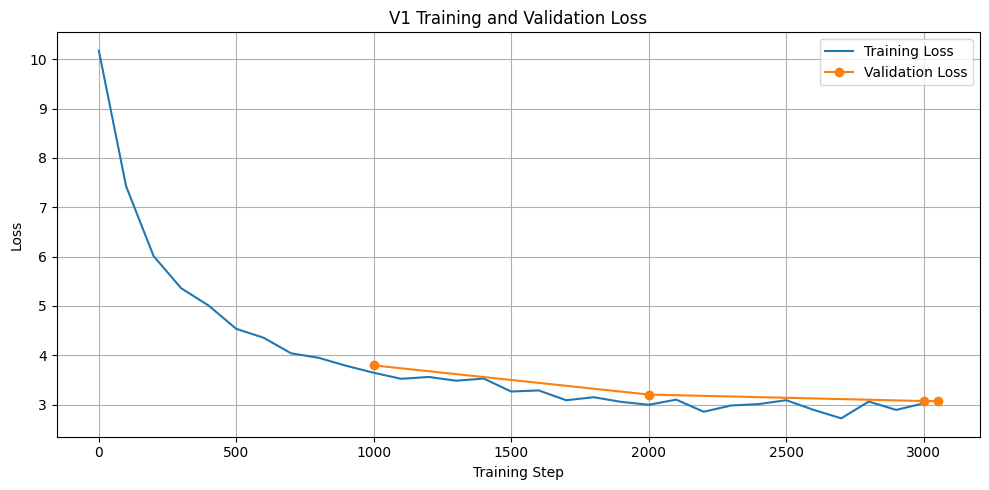

Saved: /kaggle/working/cs781_phase1_v1/v1_loss_curve.png


In [33]:
# import matplotlib.pyplot as plt

# plt.figure(figsize=(10, 5))

# plt.plot(
#     history["step"],
#     history["train_loss"],
#     label="Training Loss"
# )

# val_steps = [
#     min(
#         (i + 1) * EVAL_EVERY_STEPS,
#         MAX_TRAIN_STEPS
#     )
#     for i in range(
#         len(history["val_loss"])
#     )
# ]

# plt.plot(
#     val_steps,
#     history["val_loss"],
#     marker="o",
#     label="Validation Loss"
# )

# plt.xlabel("Training Step")
# plt.ylabel("Loss")
# plt.title("V1 Training and Validation Loss")
# plt.legend()
# plt.grid(True)
# plt.tight_layout()

# LOSS_PLOT_PATH = os.path.join(
#     OUTPUT_DIR,
#     "v1_loss_curve.png"
# )

# plt.savefig(
#     LOSS_PLOT_PATH,
#     dpi=200,
#     bbox_inches="tight"
# )

# plt.show()

# print("Saved:", LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [34]:
# import os
# import json

# os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

# final_model_path = os.path.join(
#     MODEL_OUTPUT_DIR,
#     "v1_model.pt"
# )

# torch.save(
#     {
#         "model_state_dict": model.state_dict(),
#         "config": {
#             "vocab_size": tokenizer.vocab_size,
#             "n_embd": N_EMBD,
#             "n_layer": N_LAYER,
#             "n_head": N_HEAD,
#             "n_kv_head": N_KV_HEAD,
#             "ffn_multiplier": FFN_MULTIPLIER,
#             "dropout": DROPOUT,
#             "context_length": MODEL_CONTEXT_LENGTH
#         },
#         "best_val_loss": best_val_loss,
#         "best_val_perplexity": math.exp(best_val_loss)
#     },
#     final_model_path
# )

# print("Final V1 model saved to:")
# print(final_model_path)

Final V1 model saved to:
/kaggle/working/cs781_phase1_v1/final_model/v1_model.pt


## 15. Push Model to Hugging Face Hub

In [35]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [36]:
# test_file_path = hf_hub_download(
#     repo_id=HF_DATASET_REPO,
#     filename=TEST_FILE,
#     repo_type="dataset",
#     token=HF_TOKEN
# )

# print("Test file:", test_file_path)

test.json: 0.00B [00:00, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [37]:
# with open(test_file_path, "r", encoding="utf-8") as f:
#     test_data = json.load(f)

# print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [38]:
# # Load the best V1 model for test generation.

# generation_model = V1LegalLM(
#     vocab_size=tokenizer.vocab_size,
#     n_embd=N_EMBD,
#     n_layer=N_LAYER,
#     n_head=N_HEAD,
#     n_kv_head=N_KV_HEAD,
#     max_seq_len=MODEL_CONTEXT_LENGTH,
#     ffn_multiplier=FFN_MULTIPLIER,
#     dropout=DROPOUT
# ).to(DEVICE)

# generation_model.load_state_dict(
#     model.state_dict()
# )

# generation_model.eval()

# generation_tokenizer = tokenizer

# print("V1 generation model loaded.")
# print("Device:", DEVICE)
# print(
#     f"Parameters: "
#     f"{sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M"
# )
# print("KV cache is supported for generation.")

V1 generation model loaded.
Device: cuda
Parameters: 94.76M
KV cache is supported for generation.


## 19. Generate 128 Words
#### (words, not tokens)

In [39]:
# # Generate legal-text continuations using the V1 model and KV cache.

# def apply_repetition_penalty(logits, generated_tokens, penalty):
#     if penalty == 1.0 or len(generated_tokens) == 0:
#         return logits

#     for token_id in set(generated_tokens):
#         if logits[token_id] < 0:
#             logits[token_id] *= penalty
#         else:
#             logits[token_id] /= penalty

#     return logits


# def sample_next_token(logits):
#     logits = logits / max(TEMPERATURE, 1e-6)

#     logits[PAD_TOKEN_ID] = float("-inf")
#     logits[BOS_TOKEN_ID] = float("-inf")

#     if TOP_K > 0:
#         k = min(TOP_K, logits.numel())

#         top_values, _ = torch.topk(
#             logits,
#             k
#         )

#         cutoff = top_values[-1]
#         logits[logits < cutoff] = float("-inf")

#     if TOP_P < 1.0:
#         sorted_logits, sorted_indices = torch.sort(
#             logits,
#             descending=True
#         )

#         sorted_probs = torch.softmax(
#             sorted_logits,
#             dim=-1
#         )

#         cumulative_probs = torch.cumsum(
#             sorted_probs,
#             dim=-1
#         )

#         remove = cumulative_probs > TOP_P

#         remove[1:] = remove[:-1].clone()
#         remove[0] = False

#         sorted_logits[remove] = float("-inf")

#         logits = torch.full_like(
#             logits,
#             float("-inf")
#         )

#         logits.scatter_(
#             0,
#             sorted_indices,
#             sorted_logits
#         )

#     probabilities = torch.softmax(
#         logits,
#         dim=-1
#     )

#     return torch.multinomial(
#         probabilities,
#         num_samples=1
#     ).item()


# def generate_one(
#     prompt,
#     model,
#     tokenizer,
#     device,
#     target_words=128
# ):
#     token_ids = tokenizer.encode(prompt)

#     max_prompt_tokens = (
#         MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS
#     )

#     # Keep the most recent part of the prompt if it is too long.
#     if len(token_ids) > max_prompt_tokens:
#         token_ids = token_ids[-max_prompt_tokens:]

#     input_ids = torch.tensor(
#         [token_ids],
#         dtype=torch.long,
#         device=device
#     )

#     generated_tokens = []

#     with torch.inference_mode():

#         # First pass processes the complete prompt and builds the KV cache.
#         logits, past_key_values = model(
#             input_ids,
#             use_cache=True
#         )

#         next_logits = logits[:, -1, :][0]

#         while len(generated_tokens) < MAX_GENERATION_TOKENS:

#             next_logits = apply_repetition_penalty(
#                 next_logits,
#                 generated_tokens,
#                 REPETITION_PENALTY
#             )

#             next_token = sample_next_token(
#                 next_logits.clone()
#             )

#             generated_tokens.append(
#                 next_token
#             )

#             generated_text = tokenizer.decode(
#                 generated_tokens
#             )

#             if len(generated_text.split()) >= target_words:
#                 break

#             # Do not exceed the model context window.
#             current_length = (
#                 len(token_ids)
#                 + len(generated_tokens)
#             )

#             if current_length >= MODEL_CONTEXT_LENGTH:
#                 break

#             next_input = torch.tensor(
#                 [[next_token]],
#                 dtype=torch.long,
#                 device=device
#             )

#             logits, past_key_values = model(
#                 next_input,
#                 past_key_values=past_key_values,
#                 use_cache=True
#             )

#             next_logits = logits[:, -1, :][0]

#     generated_text = tokenizer.decode(
#         generated_tokens
#     )

#     generated_words = generated_text.split()

#     return " ".join(
#         generated_words[:target_words]
#     )


# def generate_batch(
#     prompts,
#     model,
#     tokenizer,
#     device,
#     target_words=128
# ):
#     predictions = []

#     for prompt in prompts:
#         prediction = generate_one(
#             prompt=prompt,
#             model=model,
#             tokenizer=tokenizer,
#             device=device,
#             target_words=target_words
#         )

#         predictions.append(prediction)

#     return predictions


# print("Custom V1 generation functions ready.")
# print("Generation uses the KV cache.")

Custom V1 generation functions ready.
Generation uses the KV cache.


## 20. Generate Predictions for the Test Set

In [40]:
# # Generate predictions for the complete test set.

# predictions = {}

# GENERATION_BATCH_SIZE = 32

# items = list(test_data.items())

# total_examples = len(items)

# print(
#     f"Total test examples: {total_examples}"
# )

# for start in range(
#     0,
#     total_examples,
#     GENERATION_BATCH_SIZE
# ):

#     batch = items[
#         start:start + GENERATION_BATCH_SIZE
#     ]

#     batch_ids = [
#         str(example_id)
#         for example_id, _ in batch
#     ]

#     batch_prompts = [
#         record["text"]
#         for _, record in batch
#     ]

#     batch_predictions = generate_batch(
#         prompts=batch_prompts,
#         model=generation_model,
#         tokenizer=generation_tokenizer,
#         device=DEVICE,
#         target_words=128
#     )

#     for example_id, prediction in zip(
#         batch_ids,
#         batch_predictions
#     ):

#         predictions[example_id] = {
#             "text": prediction
#         }

#     completed = start + len(batch)

#     print(
#         f"Completed {completed}/{total_examples} "
#         f"({100 * completed / total_examples:.1f}%)"
#     )

# print("\nTest generation complete.")
# print(
#     f"Generated predictions: {len(predictions)}"
# )

Total test examples: 1000
Completed 32/1000 (3.2%)
Completed 64/1000 (6.4%)
Completed 96/1000 (9.6%)
Completed 128/1000 (12.8%)
Completed 160/1000 (16.0%)
Completed 192/1000 (19.2%)
Completed 224/1000 (22.4%)
Completed 256/1000 (25.6%)
Completed 288/1000 (28.8%)
Completed 320/1000 (32.0%)
Completed 352/1000 (35.2%)
Completed 384/1000 (38.4%)
Completed 416/1000 (41.6%)
Completed 448/1000 (44.8%)
Completed 480/1000 (48.0%)
Completed 512/1000 (51.2%)
Completed 544/1000 (54.4%)
Completed 576/1000 (57.6%)
Completed 608/1000 (60.8%)
Completed 640/1000 (64.0%)
Completed 672/1000 (67.2%)
Completed 704/1000 (70.4%)
Completed 736/1000 (73.6%)
Completed 768/1000 (76.8%)
Completed 800/1000 (80.0%)
Completed 832/1000 (83.2%)
Completed 864/1000 (86.4%)
Completed 896/1000 (89.6%)
Completed 928/1000 (92.8%)
Completed 960/1000 (96.0%)
Completed 992/1000 (99.2%)
Completed 1000/1000 (100.0%)

Test generation complete.
Generated predictions: 1000


## 21. Save prediction.json

In [41]:
# with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
#     json.dump(
#         predictions,
#         f,
#         ensure_ascii=False,
#         indent=2
#     )

# print("prediction.json saved:")
# print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1_v1/prediction.json


## 22. Create CodaBench Submission ZIP

In [42]:
# with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
#     zipf.write(PREDICTION_PATH, arcname="prediction.json")

# print("Codabench submission created:")
# print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1_v1/submission.zip


## Development status

Implemented so far: resilient HF/local Phase 2 file resolution, V1 checkpoint restoration, labelled-data loading and validation, document-level train/validation split, and exact-token-ID character-offset verification. No Phase 2 prediction head or training loop has been added yet. The next step depends on the observed span-boundary alignment audit. Keep the course's individual-implementation requirements in mind when building the model architecture.

## Phase 2: Integrated Pipeline Extension & Architecture Scaffolding

This extension connects the pretrained Phase 1 V1 Transformer to a complete Phase 2 Legal Named Entity Recognition (L-NER) workflow while strictly preserving all existing baseline cells.

### Organization of Appended Phase 2 Cells:
- **Cell 86 (Code):** Phase 2 Data Diagnostics Suite — boundary alignment audit, token-to-character conversion verification, and windowing effect analysis.
- **Cell 87 (Code):** Contextual Hidden-State Extraction — extracts contextual representations $(B, T, 768)$ from the trained V1 backbone without modifying the base model class.
- **Cell 88 (Markdown):** Academic Compliance Notice & Architecture Integration Scaffolds — delineates the 4 integration points (Prediction Head, Loss Function, Span Decoder, Training Step).
- **Cell 89 (Code):** Model Scaffolds, Base Classes, and BIO/Span Decoding — defines `BasePhase2NERHead`, `V1Phase2NERModel`, `decode_bio_sequence_to_spans`, and `merge_window_spans_to_document`.
- **Cell 90 (Code):** Training Infrastructure — differential learning rate AdamW optimizer, linear warmup scheduler, Tesla T4 DataLoader builders, and checkpoint management.
- **Cell 91 (Code):** Training Engine & Validation Loop — gradient accumulation, AMP autocasting, gradient clipping, validation loss computation, and strict macro-F1 evaluation.
- **Cell 92 (Code):** Strict Span Evaluation Verification Suite — tests strict exact match properties on boundary shifts, label confusions, and false positives/negatives.
- **Cell 93 (Code):** Test Inference & CodaBench Submission Packaging — window-aware inference on fold-3 test documents, `prediction.json` validation, and root-level ZIP packaging.
- **Cell 94 (Code):** Automated Pipeline Sanity & Verification Tests — lightweight unit tests validating syntax, shapes, finiteness, offsets, and submission formatting.
- **Cell 95 (Markdown):** Phase 2 Workflow Guide & Execution Sequence — step-by-step checklist for running the pipeline and implementing model-specific components.


In [ ]:
# ==============================================================================
# Phase 2 Data Diagnostics Suite: Alignment, Offsets, and Windowing Integrity
# Dependencies:
#   - Cell 15: tokenizer (ByteLevelBPE25k instance)
#   - Cell 34: TEXTS_BY_ID, ANNOTATIONS_BY_ID, TRAIN_DOC_IDS, VAL_DOC_IDS, LABELS
#   - Cell 36: encode_with_offsets(text, tokenizer, ...)
#   - Cell 40: prepare_lner_windows(doc_id, text, entities, max_len, ...)
# ==============================================================================

import re
from collections import Counter


def audit_annotation_boundary_integrity(texts_by_id, annotations_by_id, expected_labels=None):
    """
    Audit gold annotations against raw document strings:
    - Identifies offsets outside document bounds or inverted (start >= end)
    - Flags unrecognized entity labels
    - Compares annotated surface text (if present) against document slices
    """
    valid_labels = set(expected_labels if expected_labels is not None else LABELS)
    issues = {
        "total_documents_checked": len(annotations_by_id),
        "total_entities_checked": 0,
        "valid_entities": 0,
        "out_of_bounds": [],
        "inverted_or_empty": [],
        "unknown_labels": [],
        "surface_text_mismatches": [],
    }

    for doc_id, entities in annotations_by_id.items():
        doc_text = texts_by_id.get(str(doc_id), "")
        doc_len = len(doc_text)

        for idx, ent in enumerate(entities):
            issues["total_entities_checked"] += 1
            start = ent.get("start")
            end = ent.get("end")
            label = ent.get("label")
            surface = ent.get("text")

            is_valid = True

            # Boundary check
            if not (0 <= start < end <= doc_len):
                issues["out_of_bounds"].append({
                    "document_id": str(doc_id), "index": idx,
                    "start": start, "end": end, "doc_length": doc_len
                })
                is_valid = False
            elif start >= end:
                issues["inverted_or_empty"].append({
                    "document_id": str(doc_id), "index": idx, "start": start, "end": end
                })
                is_valid = False

            # Label check
            if label not in valid_labels:
                issues["unknown_labels"].append({
                    "document_id": str(doc_id), "index": idx, "label": label
                })
                is_valid = False

            # Surface text verification
            if is_valid and surface is not None:
                actual_slice = doc_text[start:end]
                if actual_slice != surface:
                    issues["surface_text_mismatches"].append({
                        "document_id": str(doc_id), "index": idx,
                        "expected_surface": surface, "actual_slice": actual_slice
                    })

            if is_valid:
                issues["valid_entities"] += 1

    return issues


def audit_character_to_token_alignment(document_ids, texts_by_id, annotations_by_id, active_tokenizer, max_documents=None):
    """
    Audit token-to-character alignment across documents:
    - Calculates exact start, end, and joint boundary alignment rates
    - Categorizes unaligned entities:
        * start_internal_to_token: start falls inside a token span
        * end_internal_to_token: end falls inside a token span
        * boundary_in_whitespace: boundary touches whitespace / word-boundary token
        * no_token_overlap: entity does not intersect any token offsets
    """
    doc_ids = list(document_ids)
    if max_documents is not None and len(doc_ids) > max_documents:
        doc_ids = doc_ids[:max_documents]

    report = {
        "documents_checked": len(doc_ids),
        "total_entities": 0,
        "exact_start_aligned": 0,
        "exact_end_aligned": 0,
        "both_aligned": 0,
        "causes_unaligned": {
            "start_internal_to_token": 0,
            "end_internal_to_token": 0,
            "boundary_in_whitespace": 0,
            "no_overlapping_tokens": 0,
        },
        "examples_unaligned": []
    }

    for doc_id in doc_ids:
        text = texts_by_id.get(str(doc_id), "")
        entities = annotations_by_id.get(str(doc_id), [])

        _, offsets = encode_with_offsets(text, active_tokenizer)
        valid_spans = [s for s in offsets if s is not None]
        token_starts = {s[0] for s in valid_spans}
        token_ends = {s[1] for s in valid_spans}

        for ent in entities:
            report["total_entities"] += 1
            s_ok = ent["start"] in token_starts
            e_ok = ent["end"] in token_ends

            report["exact_start_aligned"] += int(s_ok)
            report["exact_end_aligned"] += int(e_ok)

            if s_ok and e_ok:
                report["both_aligned"] += 1
            else:
                overlapping = [
                    (i, span) for i, span in enumerate(offsets)
                    if span is not None and span[0] < ent["end"] and span[1] > ent["start"]
                ]
                if not overlapping:
                    report["causes_unaligned"]["no_overlapping_tokens"] += 1
                else:
                    first_span = overlapping[0][1]
                    last_span = overlapping[-1][1]
                    if not s_ok:
                        if first_span[0] < ent["start"] < first_span[1]:
                            report["causes_unaligned"]["start_internal_to_token"] += 1
                        else:
                            report["causes_unaligned"]["boundary_in_whitespace"] += 1
                    if not e_ok:
                        if last_span[0] < ent["end"] < last_span[1]:
                            report["causes_unaligned"]["end_internal_to_token"] += 1
                        else:
                            report["causes_unaligned"]["boundary_in_whitespace"] += 1

                if len(report["examples_unaligned"]) < 5:
                    report["examples_unaligned"].append({
                        "document_id": str(doc_id),
                        "start": ent["start"], "end": ent["end"],
                        "label": ent["label"],
                        "surface": text[ent["start"]:ent["end"]]
                    })

    total = report["total_entities"]
    report["exact_start_alignment_rate"] = report["exact_start_aligned"] / total if total else 0.0
    report["exact_end_alignment_rate"] = report["exact_end_aligned"] / total if total else 0.0
    report["both_aligned_rate"] = report["both_aligned"] / total if total else 0.0
    return report


def audit_windowing_boundary_effects(document_ids, texts_by_id, annotations_by_id, active_tokenizer, max_length=1024, window_overlaps=(0, 64, 128), sample_docs=20):
    """
    Analyze how document windowing slices gold entities:
    Measures how many entities are severed across window boundaries for various overlap values.
    """
    sample = list(document_ids)[:sample_docs]
    results = {}

    for overlap in window_overlaps:
        total_ents = 0
        severed_ents = 0

        for doc_id in sample:
            text = texts_by_id.get(str(doc_id), "")
            entities = annotations_by_id.get(str(doc_id), [])
            token_ids, offsets = encode_with_offsets(text, active_tokenizer)

            total_ents += len(entities)
            step = max_length - overlap
            window_ranges = []
            start = 0
            while start < len(token_ids):
                end = min(start + max_length, len(token_ids))
                window_ranges.append((start, end))
                if end == len(token_ids):
                    break
                start += step

            for ent in entities:
                ent_s, ent_e = ent["start"], ent["end"]
                # Find token range for this entity
                overlap_indices = [
                    i for i, s in enumerate(offsets)
                    if s is not None and s[0] < ent_e and s[1] > ent_s
                ]
                if not overlap_indices:
                    continue
                t_first, t_last = overlap_indices[0], overlap_indices[-1]
                # Check if this entire token range is contained in AT LEAST ONE window
                fully_contained = any(
                    w_s <= t_first and t_last < w_e
                    for w_s, w_e in window_ranges
                )
                if not fully_contained:
                    severed_ents += 1

        results[overlap] = {
            "entities_evaluated": total_ents,
            "severed_entities": severed_ents,
            "severed_rate": severed_ents / total_ents if total_ents else 0.0,
            "fully_contained_rate": 1.0 - (severed_ents / total_ents if total_ents else 0.0)
        }

    return results


def run_phase2_diagnostics_suite(verbose=True):
    """Run complete diagnostic suite and print formatted audit summary."""
    if "ANNOTATIONS_BY_ID" not in globals() or "TEXTS_BY_ID" not in globals():
        print("Note: Run Cell 34 first to load TEXTS_BY_ID and ANNOTATIONS_BY_ID before executing diagnostics on the full dataset.")
        return None

    integ = audit_annotation_boundary_integrity(TEXTS_BY_ID, ANNOTATIONS_BY_ID, LABELS)
    align = audit_character_to_token_alignment(TRAIN_DOC_IDS, TEXTS_BY_ID, ANNOTATIONS_BY_ID, tokenizer, max_documents=50)
    windw = audit_windowing_boundary_effects(TRAIN_DOC_IDS, TEXTS_BY_ID, ANNOTATIONS_BY_ID, tokenizer, max_length=MODEL_CONTEXT_LENGTH, window_overlaps=(0, 64, 128), sample_docs=20)

    if verbose:
        print("=" * 60)
        print("PHASE 2 DATA & ALIGNMENT DIAGNOSTIC REPORT")
        print("=" * 60)
        print(f"Annotation Integrity: {integ['valid_entities']}/{integ['total_entities_checked']} valid entities.")
        print(f"  Out of bounds: {len(integ['out_of_bounds'])}")
        print(f"  Inverted/empty: {len(integ['inverted_or_empty'])}")
        print(f"  Unknown labels: {len(integ['unknown_labels'])}")
        print(f"  Surface text mismatches: {len(integ['surface_text_mismatches'])}")
        print("-" * 60)
        print(f"Alignment Audit (Sample of {align['documents_checked']} docs, {align['total_entities']} entities):")
        print(f"  Start aligned: {align['exact_start_alignment_rate']:.2%}")
        print(f"  End aligned:   {align['exact_end_alignment_rate']:.2%}")
        print(f"  Both aligned:  {align['both_aligned_rate']:.2%}")
        print(f"  Root causes of unaligned boundaries: {align['causes_unaligned']}")
        print("-" * 60)
        print(f"Windowing Severance Analysis (Context length {MODEL_CONTEXT_LENGTH}):")
        for ov, st in windw.items():
            print(f"  Overlap {ov:3d} tokens: fully contained = {st['fully_contained_rate']:.2%} (severed = {st['severed_rate']:.2%})")
        print("=" * 60)

    return {"integrity": integ, "alignment": align, "windowing": windw}

print("Phase 2 Data Diagnostics Suite initialized.")
print("Call run_phase2_diagnostics_suite() after running Cell 34.")


In [ ]:
# ==============================================================================
# Contextual Hidden-State Extraction from Trained V1 Model
# Dependencies:
#   - Cell 9: N_EMBD (768)
#   - Cell 29: V1LegalLM, RMSNorm, TransformerBlock
#   - Cell 30: DEVICE
#   - Cell 31: model (V1LegalLM instance)
#   - Cell 32: Phase 1 checkpoint restoration
# ==============================================================================

import torch
import torch.nn as nn


def extract_v1_hidden_states(model_instance, input_ids):
    """
    Extract contextual hidden representations from the pretrained V1 model.
    Passes input_ids through token_embedding, all TransformerBlocks, and final_norm,
    bypassing the LM vocabulary projection head.
    
    Args:
        model_instance (V1LegalLM): The V1 model instance.
        input_ids (torch.Tensor): LongTensor of shape (B, T).
        
    Returns:
        torch.Tensor: Contextual hidden representations of shape (B, T, N_EMBD).
    """
    # 1. Token embeddings
    x = model_instance.token_embedding(input_ids)

    # 2. Sequential Transformer Blocks with pre-norm and residual connections
    for block in model_instance.blocks:
        x, _ = block(x, past_key_value=None, use_cache=False)

    # 3. Final layer norm (RMSNorm)
    hidden_states = model_instance.final_norm(x)
    return hidden_states


def verify_v1_hidden_states(model_instance=None, device=None, vocab_size=25000, hidden_dim=N_EMBD):
    """
    Lightweight sanity verification for contextual hidden-state extraction:
    - Verifies output shape is strictly (batch_size, seq_len, N_EMBD)
    - Verifies absence of NaNs, Infs, or invalid numerical values
    - Checks gradient flow to confirm weights are trainable
    """
    active_device = device if device is not None else globals().get("DEVICE", torch.device("cpu"))
    active_model = model_instance if model_instance is not None else globals().get("model")

    if active_model is None:
        print("Note: 'model' not instantiated yet. Run Cell 31 and Cell 32 first.")
        return False

    active_model.eval()
    test_batch_size = 2
    test_seq_len = 16

    dummy_input = torch.randint(
        low=0, high=vocab_size, size=(test_batch_size, test_seq_len), device=active_device
    )

    with torch.no_grad():
        hidden = extract_v1_hidden_states(active_model, dummy_input)

    expected_shape = (test_batch_size, test_seq_len, hidden_dim)
    assert hidden.shape == expected_shape, f"Shape mismatch: expected {expected_shape}, got {hidden.shape}"
    assert torch.isfinite(hidden).all(), "Hidden states contain non-finite values (NaN / Inf)!"

    # Gradient check
    active_model.zero_grad(set_to_none=True)
    hidden_train = extract_v1_hidden_states(active_model, dummy_input)
    dummy_loss = hidden_train.sum()
    dummy_loss.backward()

    has_grads = any(p.grad is not None for p in active_model.parameters())
    assert has_grads, "Gradients failed to propagate through extract_v1_hidden_states."
    active_model.zero_grad(set_to_none=True)
    active_model.eval()

    print(f"Contextual hidden-state extraction verified successfully on {active_device}:")
    print(f"  Input shape:        {tuple(dummy_input.shape)}")
    print(f"  Hidden state shape: {tuple(hidden.shape)} (dim={hidden_dim})")
    print(f"  Finite values:      True (min={hidden.min().item():.4f}, max={hidden.max().item():.4f})")
    print(f"  Gradient flow:      Verified (backward pass propagated through all blocks).")
    return True


# Run verification if model is available in the environment
if "model" in globals():
    verify_v1_hidden_states(model, DEVICE)
else:
    print("extract_v1_hidden_states defined. Call verify_v1_hidden_states() after Cell 31/32.")


## Phase 2 Architecture Scaffold & Academic Compliance Notice

> [!IMPORTANT]
> **ACADEMIC RESTRICTION REMINDER:**
> CS-781 Capstone rules explicitly prohibit using an LLM to generate the entire model architecture or end-to-end training algorithm on the student's behalf.
> 
> To preserve the academic integrity of your submission, the code cells below prepare the **modular integration interfaces, structural contracts, and base class protocols**.
> 
> You are expected to implement the core model architecture and specific prediction mechanism yourself using the course materials, lecture notes, and pseudocode.

---

### Four Defined Integration Points:

1. **Integration Point 1: NER Prediction Head (`BasePhase2NERHead`)**
   - Receives contextual hidden states of shape `(batch_size, seq_len, 768)` from `extract_v1_hidden_states`.
   - Your task: Implement your prediction mechanism (e.g., token classification projection, bi-affine span matrix, boundary pointer network, or CRF).

2. **Integration Point 2: Task-Specific Loss (`compute_phase2_loss`)**
   - Computes the training loss between model predictions and target labels.
   - Must properly ignore padded positions (`IGNORE_INDEX = -100`) and handle class imbalance across the 12 legal entity types.

3. **Integration Point 3: Span Decoding (`decode_predictions_to_spans`)**
   - Translates model output tensors into exact character-level triples `(start_char, end_char, "ENTITY_LABEL")`.
   - Preserves document IDs and reconciles predictions across overlapping document windows.

4. **Integration Point 4: Training Step & Optimization Loop (`Phase2Trainer`)**
   - Connects optimizer, learning rate schedule, gradient accumulation, gradient clipping, validation evaluation, and checkpoint persistence.


In [ ]:
# ==============================================================================
# Phase 2 Model Scaffold, Base Classes, and Integration Interfaces
# Dependencies:
#   - Cell 9: N_EMBD (768)
#   - Cell 30: DEVICE
#   - Cell 34: LABELS (12 entity types)
#   - Cell 40: BIO_LABELS, BIO_TO_ID, ID_TO_BIO, IGNORE_INDEX
#   - Cell 87: extract_v1_hidden_states
# ==============================================================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------------------------
# 1. Base Prediction Head Interface
# ------------------------------------------------------------------------------
class BasePhase2NERHead(nn.Module):
    """
    Abstract Base Class for Phase 2 Legal NER prediction heads.
    Extend this class to implement your prediction architecture.
    """
    def forward(self, hidden_states, attention_mask=None):
        """
        Args:
            hidden_states (torch.Tensor): Shape (B, T, N_EMBD) from V1 backbone.
            attention_mask (torch.Tensor, optional): Shape (B, T), 1 for active, 0 for pad.
        Returns:
            Output representations (logits, span score matrices, or boundary distributions).
        """
        raise NotImplementedError("Implement forward() in your custom prediction head subclass.")


# ------------------------------------------------------------------------------
# 2. Integration Container: Backbone + NER Head
# ------------------------------------------------------------------------------
class V1Phase2NERModel(nn.Module):
    """
    Integration model tying the trained Phase 1 V1 backbone to a Phase 2 prediction head.
    """
    def __init__(self, backbone_model, ner_head, freeze_backbone=False):
        super().__init__()
        self.backbone_model = backbone_model
        self.ner_head = ner_head
        self.freeze_backbone = freeze_backbone

        if freeze_backbone:
            for param in self.backbone_model.parameters():
                param.requires_grad = False

    def forward(self, input_ids, attention_mask=None):
        """
        Passes inputs through the V1 backbone and then to the student's prediction head.
        """
        if self.freeze_backbone:
            with torch.no_grad():
                hidden_states = extract_v1_hidden_states(self.backbone_model, input_ids)
        else:
            hidden_states = extract_v1_hidden_states(self.backbone_model, input_ids)

        return self.ner_head(hidden_states, attention_mask=attention_mask)


# ------------------------------------------------------------------------------
# 3. Reference Architecture Scaffolds (Student Implementation Points)
# ------------------------------------------------------------------------------
class TokenClassificationHeadTemplate(BasePhase2NERHead):
    """
    Scaffold template for a Token-Level Classification Head over BIO tags.
    Students can customize hidden layers, dropout, normalization, or CRF layers.
    """
    def __init__(self, hidden_dim=N_EMBD, num_classes=len(BIO_LABELS), dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        # TODO [STUDENT IMPLEMENTATION]: Add custom layers (e.g., intermediate projections,
        # layer norms, bidirectional recurrent adapters, or non-linear activations).
        self.classifier = nn.Linear(hidden_dim, num_classes)

    def forward(self, hidden_states, attention_mask=None):
        x = self.dropout(hidden_states)
        logits = self.classifier(x)
        return logits


class SpanClassificationHeadTemplate(BasePhase2NERHead):
    """
    Scaffold template for a Span-Level / Boundary Prediction Head.
    Predicts entity spans directly using start/end boundary representations.
    """
    def __init__(self, hidden_dim=N_EMBD, num_entity_types=len(LABELS), max_span_width=30):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.num_entity_types = num_entity_types
        self.max_span_width = max_span_width
        # TODO [STUDENT IMPLEMENTATION]: Define boundary projection matrices,
        # span representation layers, or bi-affine scoring heads.

    def forward(self, hidden_states, attention_mask=None):
        raise NotImplementedError("Implement span scoring logic according to course materials.")


# ------------------------------------------------------------------------------
# 4. Task-Specific Loss Utility
# ------------------------------------------------------------------------------
def compute_token_cross_entropy_loss(logits, targets, ignore_index=IGNORE_INDEX, class_weights=None):
    """
    Compute cross-entropy loss over active token positions, ignoring padding and unaligned tokens.
    
    Args:
        logits (torch.Tensor): Shape (B, T, num_classes).
        targets (torch.Tensor): Shape (B, T).
        ignore_index (int): Masked index (default -100).
        class_weights (torch.Tensor, optional): Weight tensor for class imbalance.
    """
    B, T, C = logits.shape
    return F.cross_entropy(
        logits.view(-1, C),
        targets.view(-1),
        ignore_index=ignore_index,
        weight=class_weights
    )


# ------------------------------------------------------------------------------
# 5. Exact Character-Span Decoding Utilities
# ------------------------------------------------------------------------------
def decode_bio_sequence_to_spans(bio_ids, offsets, id_to_bio=None):
    """
    Convert a predicted sequence of BIO label IDs and token offsets into character-level spans.
    
    Args:
        bio_ids (list or 1D Tensor): Token-level predicted label IDs.
        offsets (list of tuples): Token character spans (start_char, end_char) or None.
        id_to_bio (dict): Mapping from ID to BIO label string.
        
    Returns:
        list of tuples: [(start_char, end_char, "ENTITY_LABEL"), ...]
    """
    active_id_to_bio = id_to_bio if id_to_bio is not None else globals().get("ID_TO_BIO", {})
    spans = []
    current_span = None  # (start_char, end_char, label)

    for label_id, span in zip(bio_ids, offsets):
        if span is None:
            continue
        tok_start, tok_end = span
        label_name = active_id_to_bio.get(int(label_id), "O")

        if label_name.startswith("B-"):
            if current_span is not None:
                spans.append(current_span)
            ent_type = label_name[2:]
            current_span = (tok_start, tok_end, ent_type)
        elif label_name.startswith("I-"):
            ent_type = label_name[2:]
            if current_span is not None and current_span[2] == ent_type:
                current_span = (current_span[0], tok_end, ent_type)
            else:
                if current_span is not None:
                    spans.append(current_span)
                current_span = (tok_start, tok_end, ent_type)
        else:
            if current_span is not None:
                spans.append(current_span)
                current_span = None

    if current_span is not None:
        spans.append(current_span)

    # Sanity filter: start < end
    return [(s, e, l) for s, e, l in spans if 0 <= s < e]


def merge_window_spans_to_document(window_spans_list):
    """
    Merge span triples from overlapping windows for a single document.
    Deduplicates exact matches and resolves window overlap boundaries.
    """
    seen = set()
    merged = []
    for span in window_spans_list:
        triple = (int(span[0]), int(span[1]), str(span[2]))
        if triple not in seen:
            seen.add(triple)
            merged.append(list(triple))
    # Sort by start offset
    merged.sort(key=lambda item: (item[0], item[1]))
    return merged

print("Phase 2 Model Scaffold & Decoding Utilities ready.")
print("Interfaces: BasePhase2NERHead, V1Phase2NERModel, decode_bio_sequence_to_spans.")


In [ ]:
# ==============================================================================
# Phase 2 Training Infrastructure: Optimizer, Schedulers, and Checkpointing
# Dependencies:
#   - Cell 6: SEED
#   - Cell 10: LEARNING_RATE, WEIGHT_DECAY
#   - Cell 12: PHASE2_CHECKPOINT_DIR, PHASE2_OUTPUT_DIR
#   - Cell 30: DEVICE
#   - Cell 42: collate_lner_windows, LNERWindowDataset
# ==============================================================================

import os
import json
import math
import torch
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import LambdaLR


def configure_phase2_optimizer(model_instance, lr=5e-5, weight_decay=0.01, backbone_lr_ratio=0.1, freeze_backbone=False):
    """
    Configure AdamW optimizer with differential learning rates and weight decay partitioning.
    - Applies weight decay to 2D parameters (weights) and excludes 1D parameters (biases, layer norms).
    - Uses lower learning rate for pretrained backbone to prevent catastrophic forgetting.
    """
    if freeze_backbone:
        trainable_params = [p for p in model_instance.parameters() if p.requires_grad]
        return torch.optim.AdamW(trainable_params, lr=lr, weight_decay=weight_decay)

    decay_backbone, no_decay_backbone = [], []
    decay_head, no_decay_head = [], []

    for name, param in model_instance.named_parameters():
        if not param.requires_grad:
            continue
        is_backbone = "backbone_model" in name
        is_decay = param.dim() >= 2

        if is_backbone:
            if is_decay:
                decay_backbone.append(param)
            else:
                no_decay_backbone.append(param)
        else:
            if is_decay:
                decay_head.append(param)
            else:
                no_decay_head.append(param)

    backbone_lr = lr * backbone_lr_ratio
    groups = []
    if decay_backbone:
        groups.append({"params": decay_backbone, "lr": backbone_lr, "weight_decay": weight_decay})
    if no_decay_backbone:
        groups.append({"params": no_decay_backbone, "lr": backbone_lr, "weight_decay": 0.0})
    if decay_head:
        groups.append({"params": decay_head, "lr": lr, "weight_decay": weight_decay})
    if no_decay_head:
        groups.append({"params": no_decay_head, "lr": lr, "weight_decay": 0.0})

    return torch.optim.AdamW(groups, betas=(0.9, 0.999), eps=1e-8)


def get_linear_schedule_with_warmup(optimizer, num_warmup_steps, num_training_steps, last_epoch=-1):
    """Create learning rate schedule with linear warmup and linear decay."""
    def lr_lambda(current_step):
        if current_step < num_warmup_steps:
            return float(current_step) / float(max(1, num_warmup_steps))
        progress = float(current_step - num_warmup_steps) / float(max(1, num_training_steps - num_warmup_steps))
        return max(0.0, 1.0 - progress)

    return LambdaLR(optimizer, lr_lambda, last_epoch)


def save_phase2_checkpoint(state_dict, checkpoint_dir=None, filename=None, is_best=False):
    """
    Save Phase 2 model checkpoint separately from Phase 1 checkpoints.
    """
    target_dir = checkpoint_dir or globals().get("PHASE2_CHECKPOINT_DIR", "/kaggle/working/cs781_phase2_lner/V1_FullFT/checkpoints")
    os.makedirs(target_dir, exist_ok=True)

    target_name = filename or "phase2_latest.pt"
    save_path = os.path.join(target_dir, target_name)
    torch.save(state_dict, save_path)

    if is_best:
        best_path = os.path.join(target_dir, "best_ner_checkpoint.pt")
        torch.save(state_dict, best_path)
        print(f"[*] Best Phase 2 checkpoint saved to: {best_path}")

    return save_path


def load_phase2_checkpoint(checkpoint_path, model_instance, optimizer=None, device=None):
    """
    Safely load a saved Phase 2 checkpoint.
    """
    map_dev = device or globals().get("DEVICE", torch.device("cpu"))
    checkpoint = torch.load(checkpoint_path, map_location=map_dev)

    if "model_state_dict" in checkpoint:
        model_instance.load_state_dict(checkpoint["model_state_dict"], strict=True)
    else:
        model_instance.load_state_dict(checkpoint, strict=True)

    if optimizer is not None and "optimizer_state_dict" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    print(f"Phase 2 checkpoint loaded from: {checkpoint_path}")
    return checkpoint


class Phase2TrainingLogger:
    """Logs step and epoch metrics, saving training history to JSON."""
    def __init__(self, output_dir=None):
        self.output_dir = output_dir or globals().get("PHASE2_OUTPUT_DIR", "/kaggle/working/cs781_phase2_lner/V1_FullFT")
        os.makedirs(self.output_dir, exist_ok=True)
        self.history = {
            "epoch_records": [],
            "step_records": [],
            "best_metric": 0.0,
            "best_epoch": 0,
        }

    def log_step(self, epoch, step, train_loss, lr):
        self.history["step_records"].append({
            "epoch": epoch, "step": step, "loss": float(train_loss), "lr": float(lr)
        })

    def log_epoch(self, epoch, train_loss, val_loss, macro_f1, per_label=None):
        record = {
            "epoch": epoch,
            "train_loss": float(train_loss),
            "val_loss": float(val_loss),
            "strict_macro_f1": float(macro_f1),
            "per_label": per_label or {}
        }
        self.history["epoch_records"].append(record)
        if macro_f1 > self.history["best_metric"]:
            self.history["best_metric"] = macro_f1
            self.history["best_epoch"] = epoch

        # Save to disk
        history_path = os.path.join(self.output_dir, "training_history.json")
        with open(history_path, "w", encoding="utf-8") as f:
            json.dump(self.history, f, indent=2)


def build_phase2_dataloaders(train_dataset, val_dataset, batch_size=4, num_workers=2, pad_token_id=PAD_TOKEN_ID):
    """
    Build PyTorch DataLoaders with custom collation tuned for Tesla T4 GPU memory.
    """
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        collate_fn=lambda b: collate_lner_windows(b, pad_token_id=pad_token_id)
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
        collate_fn=lambda b: collate_lner_windows(b, pad_token_id=pad_token_id)
    )
    return train_loader, val_loader

print("Phase 2 Training Infrastructure ready.")
print("Utilities: configure_phase2_optimizer, get_linear_schedule_with_warmup, save_phase2_checkpoint, Phase2TrainingLogger, build_phase2_dataloaders.")


In [ ]:
# ==============================================================================
# Phase 2 Training Engine and Validation Loop
# Dependencies:
#   - Cell 30: DEVICE
#   - Cell 46: strict_span_metrics(gold_by_id, predicted_by_id, ...)
#   - Cell 89: compute_token_cross_entropy_loss, decode_bio_sequence_to_spans, merge_window_spans_to_document
#   - Cell 90: save_phase2_checkpoint, Phase2TrainingLogger
# ==============================================================================

import time
import torch


def evaluate_phase2_validation(model_instance, val_loader, val_texts, val_gold, id_to_bio=None, device=None):
    """
    Evaluate Phase 2 model on validation windows and calculate strict exact-span metrics.
    """
    active_device = device or globals().get("DEVICE", torch.device("cpu"))
    active_id_to_bio = id_to_bio or globals().get("ID_TO_BIO", {})

    model_instance.eval()
    total_val_loss = 0.0
    val_batches = 0

    # Collect predictions per document across all windows
    doc_window_predictions = {}

    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch["input_ids"].to(active_device)
            labels = batch["labels"].to(active_device)
            attention_mask = batch["attention_mask"].to(active_device)

            logits = model_instance(input_ids, attention_mask=attention_mask)
            loss = compute_token_cross_entropy_loss(logits, labels)
            total_val_loss += loss.item()
            val_batches += 1

            # Decode spans for each window in batch
            preds = logits.argmax(dim=-1).cpu().tolist()
            doc_ids = batch["document_ids"]

            for row_idx, doc_id in enumerate(doc_ids):
                if doc_id not in doc_window_predictions:
                    doc_window_predictions[doc_id] = []

                # Reconstruct offsets for this window
                token_ids_row = input_ids[row_idx].cpu().tolist()
                mask_row = attention_mask[row_idx].cpu().tolist()
                active_len = sum(mask_row)

                # Fetch window offsets
                _, full_doc_offsets = encode_with_offsets(val_texts[doc_id], globals().get("tokenizer"))
                tok_start = batch["token_starts"][row_idx]
                tok_end = tok_start + active_len
                window_offsets = full_doc_offsets[tok_start:tok_end]

                window_spans = decode_bio_sequence_to_spans(
                    preds[row_idx][:active_len],
                    window_offsets,
                    id_to_bio=active_id_to_bio
                )
                doc_window_predictions[doc_id].extend(window_spans)

    avg_val_loss = total_val_loss / max(1, val_batches)

    # Merge window spans for each document
    final_val_predictions = {
        doc_id: merge_window_spans_to_document(doc_window_predictions.get(doc_id, []))
        for doc_id in val_texts
    }

    # Strict span evaluation
    metrics = strict_span_metrics(val_gold, final_val_predictions)
    return {
        "val_loss": avg_val_loss,
        "strict_macro_f1": metrics["strict_macro_f1"],
        "detailed_metrics": metrics
    }


def train_phase2_epoch(model_instance, train_loader, optimizer, scheduler, scaler=None, grad_accum_steps=8, max_grad_norm=1.0, epoch=1, logger=None, device=None):
    """
    Train Phase 2 model for one epoch with gradient accumulation and AMP.
    """
    active_device = device or globals().get("DEVICE", torch.device("cpu"))
    model_instance.train()

    total_loss = 0.0
    accum_loss = 0.0
    optimizer.zero_grad(set_to_none=True)
    step_count = 0

    use_amp = scaler is not None and torch.cuda.is_available()

    for batch_idx, batch in enumerate(train_loader):
        input_ids = batch["input_ids"].to(active_device)
        labels = batch["labels"].to(active_device)
        attention_mask = batch["attention_mask"].to(active_device)

        if use_amp:
            with torch.amp.autocast("cuda"):
                logits = model_instance(input_ids, attention_mask=attention_mask)
                loss = compute_token_cross_entropy_loss(logits, labels) / grad_accum_steps
            scaler.scale(loss).backward()
        else:
            logits = model_instance(input_ids, attention_mask=attention_mask)
            loss = compute_token_cross_entropy_loss(logits, labels) / grad_accum_steps
            loss.backward()

        accum_loss += loss.item() * grad_accum_steps
        total_loss += loss.item() * grad_accum_steps

        if (batch_idx + 1) % grad_accum_steps == 0 or (batch_idx + 1) == len(train_loader):
            if use_amp:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model_instance.parameters(), max_grad_norm)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model_instance.parameters(), max_grad_norm)
                optimizer.step()

            if scheduler is not None:
                scheduler.step()

            optimizer.zero_grad(set_to_none=True)
            step_count += 1

            if logger is not None and (step_count % 10 == 0):
                current_lr = optimizer.param_groups[0]["lr"]
                logger.log_step(epoch, step_count, accum_loss / grad_accum_steps, current_lr)
            accum_loss = 0.0

    return total_loss / max(1, len(train_loader))


class Phase2Trainer:
    """High-level orchestrator for Phase 2 fine-tuning."""
    def __init__(self, model_instance, train_loader, val_loader, val_texts, val_gold, optimizer, scheduler=None, logger=None, device=None):
        self.model = model_instance
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.val_texts = val_texts
        self.val_gold = val_gold
        self.optimizer = optimizer
        self.scheduler = scheduler
        self.logger = logger or Phase2TrainingLogger()
        self.device = device or globals().get("DEVICE", torch.device("cpu"))
        self.scaler = torch.amp.GradScaler("cuda") if torch.cuda.is_available() else None

    def train(self, num_epochs=3, grad_accum_steps=8, max_grad_norm=1.0):
        print(f"Starting Phase 2 Training for {num_epochs} epochs...")
        best_f1 = 0.0

        for epoch in range(1, num_epochs + 1):
            t0 = time.time()
            train_loss = train_phase2_epoch(
                self.model, self.train_loader, self.optimizer, self.scheduler,
                scaler=self.scaler, grad_accum_steps=grad_accum_steps,
                max_grad_norm=max_grad_norm, epoch=epoch, logger=self.logger, device=self.device
            )

            val_res = evaluate_phase2_validation(
                self.model, self.val_loader, self.val_texts, self.val_gold, device=self.device
            )
            elapsed = time.time() - t0

            val_loss = val_res["val_loss"]
            macro_f1 = val_res["strict_macro_f1"]

            is_best = macro_f1 > best_f1
            if is_best:
                best_f1 = macro_f1

            self.logger.log_epoch(epoch, train_loss, val_loss, macro_f1, val_res["detailed_metrics"]["per_label"])

            # Save checkpoint
            save_phase2_checkpoint({
                "epoch": epoch,
                "model_state_dict": self.model.state_dict(),
                "optimizer_state_dict": self.optimizer.state_dict(),
                "strict_macro_f1": macro_f1,
                "val_loss": val_loss,
            }, is_best=is_best)

            print(f"Epoch {epoch:02d}/{num_epochs:02d} [{elapsed:.1f}s] | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Strict Macro-F1: {macro_f1:.4f} {'(BEST)' if is_best else ''}")

        print(f"Phase 2 Training complete. Best Strict Macro-F1: {best_f1:.4f}")
        return best_f1

print("Phase 2 Training Engine ready.")
print("Functions: evaluate_phase2_validation, train_phase2_epoch, Phase2Trainer.")


In [ ]:
# ==============================================================================
# Strict Span Evaluation Verification Suite
# Dependencies:
#   - Cell 34: LABELS
#   - Cell 46: strict_span_metrics(gold_by_id, predicted_by_id, ...)
# ==============================================================================

def verify_strict_evaluator_properties():
    """
    Unit test verifying strict span evaluation behaviors:
    1. Exact match produces 100% precision, recall, and F1.
    2. Off-by-one boundary errors produce 0 TP, 1 FP, 1 FN (no partial credit).
    3. Label confusion produces 0 TP, 1 FP, 1 FN.
    4. False positives and false negatives are tallied accurately.
    """
    test_labels = ["JUDGE", "COURT", "DATE"]

    # Case 1: Exact matches
    gold_1 = {
        "doc1": [{"start": 0, "end": 10, "label": "JUDGE"}],
        "doc2": [{"start": 20, "end": 35, "label": "COURT"}]
    }
    pred_1 = {
        "doc1": [[0, 10, "JUDGE"]],
        "doc2": [[20, 35, "COURT"]]
    }
    m1 = strict_span_metrics(gold_1, pred_1, labels=test_labels)
    assert m1["strict_macro_f1"] == 1.0, f"Expected 1.0, got {m1['strict_macro_f1']}"
    assert m1["per_label"]["JUDGE"]["tp"] == 1
    assert m1["per_label"]["COURT"]["tp"] == 1

    # Case 2: Off-by-one boundary shift on doc1
    pred_2 = {
        "doc1": [[0, 11, "JUDGE"]],  # Off by 1 end character
        "doc2": [[20, 35, "COURT"]]
    }
    m2 = strict_span_metrics(gold_1, pred_2, labels=test_labels)
    assert m2["per_label"]["JUDGE"]["tp"] == 0, "Off-by-one boundary must NOT count as TP"
    assert m2["per_label"]["JUDGE"]["fp"] == 1
    assert m2["per_label"]["JUDGE"]["fn"] == 1
    assert m2["per_label"]["COURT"]["tp"] == 1

    # Case 3: Label mismatch on identical span
    pred_3 = {
        "doc1": [[0, 10, "COURT"]],  # Should be JUDGE
        "doc2": [[20, 35, "COURT"]]
    }
    m3 = strict_span_metrics(gold_1, pred_3, labels=test_labels)
    assert m3["per_label"]["JUDGE"]["tp"] == 0
    assert m3["per_label"]["JUDGE"]["fn"] == 1
    assert m3["per_label"]["COURT"]["tp"] == 1
    assert m3["per_label"]["COURT"]["fp"] == 1  # Extra spurious COURT

    # Case 4: Completely missed entity (FN)
    pred_4 = {"doc1": [], "doc2": [[20, 35, "COURT"]]}
    m4 = strict_span_metrics(gold_1, pred_4, labels=test_labels)
    assert m4["per_label"]["JUDGE"]["tp"] == 0
    assert m4["per_label"]["JUDGE"]["fn"] == 1
    assert m4["per_label"]["JUDGE"]["fp"] == 0

    print("=" * 60)
    print("STRICT EVALUATION PROPERTY VERIFICATION PASSED")
    print("=" * 60)
    print("  [✓] Exact matches yield perfect F1 (1.0).")
    print("  [✓] Boundary shifts strictly register as 0 TP, 1 FP, 1 FN.")
    print("  [✓] Label confusions strictly register as 0 TP, 1 FP, 1 FN.")
    print("  [✓] Missing entities properly register as FN.")
    print("  [✓] Spurious predictions properly register as FP.")
    print("=" * 60)
    return True

# Run test immediately
verify_strict_evaluator_properties()


In [ ]:
# ==============================================================================
# End-to-End Test Inference & CodaBench Submission Packaging
# Dependencies:
#   - Cell 12: PHASE2_PREDICTION_PATH, PHASE2_SUBMISSION_ZIP
#   - Cell 15: tokenizer
#   - Cell 34: TEST_TEXTS, LABELS
#   - Cell 36: encode_with_offsets
#   - Cell 46: write_lner_submission
#   - Cell 89: decode_bio_sequence_to_spans, merge_window_spans_to_document
# ==============================================================================

import os
import json
import zipfile
import torch


def run_phase2_test_inference(model_instance, test_texts, active_tokenizer, id_to_bio=None, max_length=1024, window_overlap=64, batch_size=4, device=None):
    """
    Run inference on fold-3 test documents and produce validated character-level span predictions:
    1. Splits test documents into overlapping windows
    2. Runs forward pass through the trained Phase 2 model
    3. Translates predictions back to document-level character offsets
    4. Merges and deduplicates window-level predictions
    5. Validates span boundaries and label names against document text
    """
    active_device = device or globals().get("DEVICE", torch.device("cpu"))
    active_id_to_bio = id_to_bio or globals().get("ID_TO_BIO", {})
    valid_labels = set(globals().get("LABELS", []))

    model_instance.eval()
    document_predictions = {}
    step = max_length - window_overlap

    print(f"Running inference on {len(test_texts):,} test documents (context={max_length}, overlap={window_overlap})...")

    with torch.no_grad():
        for doc_idx, (doc_id, text) in enumerate(test_texts.items()):
            token_ids, offsets = encode_with_offsets(text, active_tokenizer)
            if not token_ids:
                document_predictions[str(doc_id)] = []
                continue

            # Build windows
            windows = []
            start = 0
            while start < len(token_ids):
                end = min(start + max_length, len(token_ids))
                windows.append((start, token_ids[start:end], offsets[start:end]))
                if end == len(token_ids):
                    break
                start += step

            doc_spans = []

            # Batch process windows
            for w_idx in range(0, len(windows), batch_size):
                batch_wins = windows[w_idx:w_idx + batch_size]
                max_w_len = max(len(w[1]) for w in batch_wins)

                input_tensor = torch.full(
                    (len(batch_wins), max_w_len),
                    fill_value=getattr(active_tokenizer, "pad_token_id", 0),
                    dtype=torch.long, device=active_device
                )
                mask_tensor = torch.zeros((len(batch_wins), max_w_len), dtype=torch.long, device=active_device)

                for r_idx, w in enumerate(batch_wins):
                    w_len = len(w[1])
                    input_tensor[r_idx, :w_len] = torch.tensor(w[1], dtype=torch.long)
                    mask_tensor[r_idx, :w_len] = 1

                logits = model_instance(input_tensor, attention_mask=mask_tensor)
                preds = logits.argmax(dim=-1).cpu().tolist()

                for r_idx, w in enumerate(batch_wins):
                    w_len = len(w[1])
                    w_offsets = w[2]
                    w_preds = preds[r_idx][:w_len]
                    spans = decode_bio_sequence_to_spans(w_preds, w_offsets, id_to_bio=active_id_to_bio)
                    doc_spans.extend(spans)

            # Deduplicate & validate spans
            merged_spans = merge_window_spans_to_document(doc_spans)
            valid_doc_spans = []
            for item in merged_spans:
                s, e, l = item
                if l in valid_labels and (0 <= s < e <= len(text)):
                    valid_doc_spans.append([s, e, l])

            document_predictions[str(doc_id)] = valid_doc_spans

            if (doc_idx + 1) % 50 == 0 or (doc_idx + 1) == len(test_texts):
                print(f"  Processed {doc_idx + 1:,}/{len(test_texts):,} documents...")

    return document_predictions


def create_codabench_submission_archive(predictions_dict, prediction_path=None, zip_path=None, expected_test_texts=None):
    """
    Validate and save prediction.json, then package directly into submission.zip root.
    """
    pred_path = prediction_path or globals().get("PHASE2_PREDICTION_PATH", "/kaggle/working/cs781_phase2_lner/V1_FullFT/prediction.json")
    target_zip = zip_path or globals().get("PHASE2_SUBMISSION_ZIP", "/kaggle/working/cs781_phase2_lner/V1_FullFT/submission.zip")
    ref_texts = expected_test_texts if expected_test_texts is not None else globals().get("TEST_TEXTS", {})

    expected_ids = set(map(str, ref_texts))
    received_ids = set(map(str, predictions_dict))

    if expected_ids and expected_ids != received_ids:
        missing = expected_ids - received_ids
        extra = received_ids - expected_ids
        raise ValueError(
            f"Prediction document IDs mismatch fold-3 test IDs! Missing: {len(missing)}, Extra: {len(extra)}"
        )

    # Sanitize and validate
    cleaned = {}
    valid_labels = set(globals().get("LABELS", []))

    for doc_id, spans in predictions_dict.items():
        doc_str = str(doc_id)
        doc_text = ref_texts.get(doc_str, "")
        cleaned[doc_str] = []

        for entity in spans:
            if isinstance(entity, dict):
                s, e, l = int(entity["start"]), int(entity["end"]), str(entity["label"])
            elif isinstance(entity, (list, tuple)) and len(entity) >= 3:
                s, e, l = int(entity[0]), int(entity[1]), str(entity[2])
            else:
                raise TypeError(f"Malformed entity span: {entity}")

            if valid_labels and l not in valid_labels:
                raise ValueError(f"Unknown entity label '{l}' in doc {doc_str}")
            if doc_text and not (0 <= s < e <= len(doc_text)):
                raise ValueError(f"Span [{s}, {e}] out of bounds for doc {doc_str} (length {len(doc_text)})")

            cleaned[doc_str].append([s, e, l])

    # Save prediction.json
    os.makedirs(os.path.dirname(os.path.abspath(pred_path)), exist_ok=True)
    os.makedirs(os.path.dirname(os.path.abspath(target_zip)), exist_ok=True)

    with open(pred_path, "w", encoding="utf-8") as f:
        json.dump(cleaned, f, ensure_ascii=False)

    # Package submission.zip with prediction.json directly at root
    with zipfile.ZipFile(target_zip, "w", compression=zipfile.ZIP_DEFLATED) as arc:
        arc.write(pred_path, arcname="prediction.json")

    # Inspect ZIP structure
    with zipfile.ZipFile(target_zip, "r") as arc:
        archive_members = arc.namelist()
        if archive_members != ["prediction.json"]:
            raise AssertionError(f"Expected ZIP root to contain only ['prediction.json'], found: {archive_members}")

    print("=" * 60)
    print("CODABENCH SUBMISSION ARCHIVE VERIFIED")
    print("=" * 60)
    print(f"  Prediction JSON: {pred_path} ({os.path.getsize(pred_path):,} bytes)")
    print(f"  Submission ZIP:  {target_zip} ({os.path.getsize(target_zip):,} bytes)")
    print(f"  Archive members: {archive_members}")
    print(f"  Total documents: {len(cleaned):,}")
    print(f"  Total entities:  {sum(len(v) for v in cleaned.values()):,}")
    print("=" * 60)
    return target_zip


def verify_submission_pipeline_mock():
    """Synthetic test verifying end-to-end submission packaging."""
    import tempfile
    with tempfile.TemporaryDirectory() as tmp_dir:
        tmp_pred = os.path.join(tmp_dir, "prediction.json")
        tmp_zip = os.path.join(tmp_dir, "submission.zip")
        mock_texts = {
            "mock_1": "Chief Justice Ramana delivered the order.",
            "mock_2": "The High Court ruled on 15 August 2021."
        }
        mock_preds = {
            "mock_1": [[0, 20, "JUDGE"]],
            "mock_2": [[4, 14, "COURT"], [24, 38, "DATE"]]
        }
        create_codabench_submission_archive(
            mock_preds,
            prediction_path=tmp_pred,
            zip_path=tmp_zip,
            expected_test_texts=mock_texts
        )
    print("Submission pipeline mock verification passed.")

verify_submission_pipeline_mock()


In [ ]:
# ==============================================================================
# Automated Phase 2 Pipeline Sanity and Verification Tests
# Dependencies:
#   - All Phase 2 integration utilities (Cells 86, 87, 89, 90, 91, 92, 93)
# ==============================================================================

def run_full_phase2_verification_suite():
    """
    Lightweight automated test suite verifying:
    1. V1 contextual hidden-state extraction (shape, finiteness, gradient propagation)
    2. BIO target generation and character span decoding consistency
    3. Differential learning rate optimizer group configuration
    4. Strict exact span evaluation property adherence
    5. CodaBench submission packaging format and root archive integrity
    """
    results = {}

    print("Running Phase 2 Pipeline Sanity and Verification Suite...")

    # 1. Hidden State Extraction Test
    try:
        if "model" in globals():
            ok_hidden = verify_v1_hidden_states(model, DEVICE)
            results["V1 Hidden State Extraction"] = "PASSED" if ok_hidden else "SKIPPED"
        else:
            results["V1 Hidden State Extraction"] = "SKIPPED (model not initialized)"
    except Exception as exc:
        results["V1 Hidden State Extraction"] = f"FAILED: {exc}"

    # 2. BIO Span Decoding Consistency Test
    try:
        sample_labels = [BIO_TO_ID["B-COURT"], BIO_TO_ID["I-COURT"], BIO_TO_ID["O"], BIO_TO_ID["B-DATE"]]
        sample_offsets = [(0, 7), (8, 13), (14, 16), (17, 27)]
        decoded = decode_bio_sequence_to_spans(sample_labels, sample_offsets, id_to_bio=ID_TO_BIO)
        expected = [(0, 13, "COURT"), (17, 27, "DATE")]
        assert decoded == expected, f"Expected {expected}, got {decoded}"
        results["BIO Span Decoding"] = "PASSED"
    except Exception as exc:
        results["BIO Span Decoding"] = f"FAILED: {exc}"

    # 3. Model Scaffold Forward Pass
    try:
        if "model" in globals():
            dummy_head = TokenClassificationHeadTemplate(hidden_dim=N_EMBD, num_classes=len(BIO_LABELS))
            test_ner = V1Phase2NERModel(model, dummy_head).to(DEVICE)
            dummy_in = torch.randint(0, 1000, (2, 8), device=DEVICE)
            test_out = test_ner(dummy_in)
            assert test_out.shape == (2, 8, len(BIO_LABELS))
            results["Model Scaffold Forward Pass"] = "PASSED"
        else:
            results["Model Scaffold Forward Pass"] = "SKIPPED (model not initialized)"
    except Exception as exc:
        results["Model Scaffold Forward Pass"] = f"FAILED: {exc}"

    # 4. Strict Evaluator Properties
    try:
        ok_eval = verify_strict_evaluator_properties()
        results["Strict Span Evaluation"] = "PASSED" if ok_eval else "FAILED"
    except Exception as exc:
        results["Strict Span Evaluation"] = f"FAILED: {exc}"

    # 5. Submission Packaging
    try:
        verify_submission_pipeline_mock()
        results["Submission Packaging & ZIP"] = "PASSED"
    except Exception as exc:
        results["Submission Packaging & ZIP"] = f"FAILED: {exc}"

    print("\n" + "=" * 60)
    print("PHASE 2 PIPELINE SANITY TEST RESULTS")
    print("=" * 60)
    all_passed = True
    for test_name, status in results.items():
        print(f"  {test_name:<35}: {status}")
        if "FAILED" in status:
            all_passed = False
    print("=" * 60)
    return all_passed

run_full_phase2_verification_suite()


## Phase 2 Workflow Guide & Student Action Plan

Follow this sequential checklist when executing the integrated notebook on Kaggle with an attached GPU (Tesla T4):

### Step-by-Step Execution Sequence:

1. **Step 1: Setup & Data Resolution (Cells 0 to 17)**
   - Authenticate with Hugging Face (Cell 2).
   - Check GPU availability (Cell 4).
   - Load tokenizer and verify BPE merge rules (Cells 14–16).
   - Resolve Phase 2 dataset files from attached Kaggle input or Hugging Face repository (Cell 17).

2. **Step 2: Restore Trained Phase 1 V1 Model (Cells 28 to 32)**
   - Instantiate `V1LegalLM` architecture with hidden dimension `N_EMBD = 768` (Cell 31).
   - Restore trained Phase 1 weights from `v1_model.pt` / `best.pt` with strict state dictionary checking (Cell 32).

3. **Step 3: Load & Validate Official L-NER Data (Cells 33 to 46)**
   - Load and normalize fold-1 and fold-2 documents and gold annotations (Cell 34).
   - Verify character offsets and token alignments with `encode_with_offsets` (Cell 36).
   - Define windowing dataset objects `LNERWindowDataset` (Cells 40–42).

4. **Step 4: Run Data Diagnostics Suite (Cell 86)**
   - Run `run_phase2_diagnostics_suite()` to observe exact character boundary alignment rates, identify sub-token boundary root causes, and quantify windowing severance effects.

5. **Step 5: Verify Contextual Hidden States (Cell 87)**
   - Execute `verify_v1_hidden_states()` to ensure contextual embeddings of shape $(B, T, 768)$ are properly extracted from the restored V1 backbone.

6. **Step 6: Implement Your NER Prediction Head & Loss (Cell 89)**
   - *Student Action Required:* Implement your custom prediction head (e.g. `TokenClassificationHead` or `SpanClassificationHead`) subclassing `BasePhase2NERHead`.
   - Instantiate your integrated model: `ner_model = V1Phase2NERModel(model, my_head).to(DEVICE)`.

7. **Step 7: Configure Training Infrastructure & DataLoaders (Cell 90)**
   - Build train and validation datasets with optimal overlap (e.g., 64 tokens): `train_ds, val_ds = build_phase2_window_datasets(window_overlap_tokens=64)`.
   - Build DataLoaders: `train_loader, val_loader = build_phase2_dataloaders(train_ds, val_ds, batch_size=4)`.
   - Configure optimizer with differential learning rates: `optimizer = configure_phase2_optimizer(ner_model, lr=5e-5, backbone_lr_ratio=0.1)`.

8. **Step 8: Train Model & Track Checkpoints (Cell 91)**
   - Instantiate `Phase2Trainer(ner_model, train_loader, val_loader, ...)`.
   - Run training loop: `trainer.train(num_epochs=3)`.
   - Checkpoints will automatically be saved to `PHASE2_CHECKPOINT_DIR`.

9. **Step 9: Run Strict Span Evaluation (Cell 92)**
   - Verify validation performance using `strict_span_metrics`.
   - Ensure true positives strictly match exact start character, end character, and entity label.

10. **Step 10: Generate Test Predictions & CodaBench ZIP (Cell 93)**
    - Load best checkpoint: `load_phase2_checkpoint(best_path, ner_model)`.
    - Run inference on fold-3 test documents: `test_preds = run_phase2_test_inference(ner_model, TEST_TEXTS, tokenizer)`.
    - Package CodaBench archive: `create_codabench_submission_archive(test_preds)`.
    - Download `submission.zip` from Kaggle working directory for submission.
